# **Lab 2 - Tabular Datasets**

<b>Information on group members:</b><br>
1) **Kuba Czech**, 156035 <br>
2) **Wojciech Nagórka**, 156045

In [ ]:
import joblib
import numpy as np
import pandas as pd
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt

from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.feature_selection import VarianceThreshold, SelectFromModel, SelectKBest, f_classif, mutual_info_classif
from sklearn.model_selection import (
    train_test_split, 
    cross_val_predict, 
    cross_validate,
    GridSearchCV,  
    StratifiedKFold, 
    RepeatedStratifiedKFold, 
    TunedThresholdClassifierCV
)
from sklearn.metrics import (
    classification_report, 
    accuracy_score,
    precision_score,
    recall_score,
    f1_score, 
    fbeta_score,
    roc_auc_score,
    make_scorer,
    ConfusionMatrixDisplay,
    RocCurveDisplay
)

from xgboost import XGBClassifier
from catboost import CatBoostClassifier
from sklearn.linear_model import LogisticRegression

RANDOM_STATE = 42

palette = {'malignant': '#d62728', 'benign': '#1f77b4'}

## **Dataset**

The Breast Cancer Wisconsin (Diagnostic) Dataset is a classic benchmark in machine learning and biomedical data analysis. It comprises 569 instances derived from digitized images of a fine needle aspirate (FNA) of breast masses. Each record contains 30 numerical attributes that describe the visual features of the cell nuclei present in the image. These attributes are calculated from ten fundamental characteristics — such as radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension — by recording their mean, standard error, and worst-case values. The primary goal of analyzing this dataset is binary classification, specifically distinguishing between malignant and benign tumors. Due to its clean structure and well-defined features, it serves as an excellent case study for correlation analysis, dimensionality reduction, and diagnostic modeling.

In [2]:
data = load_breast_cancer()

X = pd.DataFrame(data.data, columns=data.feature_names)
y = pd.Series(data.target, name='target')

## **Exploratory Data Analysis (EDA)**

### a. Features and target

In [3]:
def target_distribution_analysis(X: pd.DataFrame, y: pd.Series):
    print(f"Samples: {X.shape[0]}, features: {X.shape[1]}")
    print(f"Missing values: {X.isna().sum().sum()}, duplicated rows: {X.duplicated().sum()}")

    print("\nTarget classes:", dict(enumerate(data.target_names)))
    print(y.value_counts().rename(index=dict(enumerate(data.target_names))).to_frame('count')
        .assign(share=lambda d: ((d['count'] / d['count'].sum())).round(3)))

def plot_target_distribution(y: pd.Series):
    y = y.map(dict(enumerate(data.target_names)))
    plt.figure(figsize=(6, 4))
    sns.countplot(x=y, hue=y, palette=palette, legend=False)
    plt.title('Target Distribution')
    plt.xlabel('Class')
    plt.ylabel('Count')
    plt.xticks(ticks=[0, 1], labels=data.target_names)
    plt.show()

Samples: 569, features: 30
Missing values: 0, duplicated rows: 0

Target classes: {0: np.str_('malignant'), 1: np.str_('benign')}
           count  share
target                 
benign       357  0.627
malignant    212  0.373


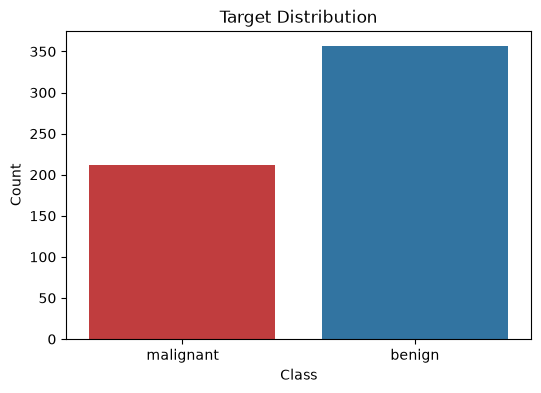

In [4]:
target_distribution_analysis(X, y)
plot_target_distribution(y)

**Key observations**:
- **Independent variables (features):** 30 continuous, numeric features describing cell nuclei computed from digitized images of fine-needle aspirates. There are 10 base measurements (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported three times.

- **Dependent variable (target):** a binary label: `0 = malignant`, `1 = benign`.

- **Class imbalance**: The dataset has 569 samples, no missing values and no duplicates. The classes are moderately imbalanced (357 benign vs 212 malignant, about 63% / 37%).

### b. Statistical analysis of the data

#### Measures of central tendency

In [5]:
central = pd.DataFrame({
    'mean': X.mean(),
    'median': X.median(),
    'mode': X.mode().iloc[0],
    'mode_count': [X[c].value_counts().iloc[0] for c in X.columns],
})
central['mean/median'] = central['mean'] / central['median']
central.round(4)

,mean,median,mode,mode_count,mean/median
mean radius,14.1273,13.3700,12.3400,4,1.0566
mean texture,19.2896,18.8400,14.9300,3,1.0239
mean perimeter,91.9690,86.2400,82.6100,3,1.0664
mean area,654.8891,551.1000,512.2000,3,1.1883
mean smoothness,0.0964,0.0959,0.1007,5,1.0051
mean compactness,0.1043,0.0926,0.1147,3,1.1264
mean concavity,0.0888,0.0615,0.0000,13,1.4430
mean concave points,0.0489,0.0335,0.0000,13,1.4603
mean symmetry,0.1812,0.1792,0.1601,4,1.0109
mean fractal dimension,0.0628,0.0615,0.0567,3,1.0204


**Key Observations:**

- For every feature the **mean is larger than the median** (ratio > 1). This points to right-skewed distributions, with a long tail of large values that pulls the mean up. The gap is largest for `area error` (mean about 40.3 vs median about 24.5) and for the `area` features.

- The **mode is not very informative** here. The features are continuous, so most values occur only 2 to 5 times. The exception is the concavity-related features (`concavity`, `concave points`, in all three variants), whose mode is **0** and occurs 13 times. These are 13 samples with no concavity at all, which is a real effect and not missing data.

#### Measures of variability

In [6]:
q1, q3 = X.quantile(0.25), X.quantile(0.75)
variability = pd.DataFrame({
    'min': X.min(),
    'max': X.max(),
    'range': X.max() - X.min(),
    'std': X.std(),
    'cv': X.std() / X.mean(),       # coefficient of variation
    'Q1': q1,                       # first quartile
    'Q3': q3,                       # third quartile
    'IQR': q3 - q1,                 # interquartile range
})
variability.round(4).sort_values('cv', ascending=False)

,min,max,range,std,cv,Q1,Q3,IQR
area error,6.8020,542.2000,535.3980,45.4910,1.1278,17.8500,45.1900,27.3400
concavity error,0.0000,0.3960,0.3960,0.0302,0.9465,0.0151,0.0420,0.0270
mean concavity,0.0000,0.4268,0.4268,0.0797,0.8978,0.0296,0.1307,0.1011
mean concave points,0.0000,0.2012,0.2012,0.0388,0.7932,0.0203,0.0740,0.0537
worst concavity,0.0000,1.2520,1.2520,0.2086,0.7665,0.1145,0.3829,0.2684
perimeter error,0.7570,21.9800,21.2230,2.0219,0.7054,1.6060,3.3570,1.7510
compactness error,0.0023,0.1354,0.1331,0.0179,0.7029,0.0131,0.0324,0.0194
fractal dimension error,0.0009,0.0298,0.0289,0.0026,0.6973,0.0022,0.0046,0.0023
radius error,0.1115,2.8730,2.7615,0.2773,0.6844,0.2324,0.4789,0.2465
worst area,185.2000,4254.0000,4068.8000,569.3570,0.6466,515.3000,1084.0000,568.7000


**Key Observations**:

- Features are on **very different scales**. For example, `worst area` ranges from about 185 to 4254, while `fractal dimension error` stays below 0.03. Therefore distance-based or gradient-based models would need scaling, while tree-based models such as XGBoost don't.

- The **coefficient of variation** (std / mean) makes features comparable regardless of scale. The most variable features are `area error` (CV about 1.13), `concavity error`, and `mean concavity` (about 0.9). Smoothness, symmetry and fractal dimension are much more stable (CV about 0.1 to 0.2).

- For most features the range is many times larger than the IQR, which suggests a few extreme observations far outside the central 50% of the data.

#### Measures of distribution shape

In exploratory data analysis, evaluating the distribution shape of continuous variables provides vital context for statistical modeling. Two fundamental metrics used to quantify these properties are **skewness** and **kurtosis**.

**Skewness** measures the degree of asymmetry in a probability distribution relative to its mean. A distribution with positive skew, or right-skewed data, features an elongated tail on the right side, indicating that the majority of observations are concentrated at lower values while a few high values pull the mean above the median. Conversely, negative skewness occurs when the tail extends toward the left, showing that most values cluster on the higher end of the scale. A skewness near zero indicates a symmetrical distribution, much like the classic bell curve of a normal distribution.

**Kurtosis**, on the other hand, quantifies the tailedness and peak sharpness of a distribution compared to a standard normal curve. Distributions with high kurtosis, known as leptokurtic distributions, display sharp peaks and heavy tails, which signals a higher probability of extreme values or outliers. In contrast, platykurtic distributions exhibit a lower kurtosis, characterized by a flatter profile and lighter tails, implying that extreme values are relatively rare. Understanding both metrics is essential for selecting appropriate data transformations and identifying underlying anomalies in numerical features.

In [7]:
shape = pd.DataFrame({
    'skewness': X.skew(),
    'kurtosis (excess)': X.kurt(),
}).sort_values('skewness', ascending=False)
shape.round(3)

,skewness,kurtosis (excess)
area error,5.447,49.209
concavity error,5.110,48.861
fractal dimension error,3.924,26.281
perimeter error,3.444,21.402
radius error,3.089,17.687
smoothness error,2.314,10.470
symmetry error,2.195,7.896
compactness error,1.902,5.106
worst area,1.859,4.396
worst fractal dimension,1.663,5.245


- **Skewness:** all 30 features are **positively (right) skewed**. The most skewed are the `error` features: `area error` (about 5.4), `concavity error` (about 5.1), `fractal dimension error` (about 3.9) and `perimeter error` (about 3.4). The closest to symmetric are the smoothness and texture features and `worst concave points` (about 0.4 to 0.6).

- **Kurtosis**: the `error` features are strongly **leptokurtic** (`area error` and `concavity error` about 49), meaning heavy tails and many extreme values. `worst concave points` has slightly negative kurtosis, so it is flatter than a normal distribution.

- Overall, the features are clearly **not normally distributed**. A log transform would help models that assume normality.

### c. Outliers

To identify anomalous data points within the dataset, the analysis applies two distinct statistical techniques: the Interquartile Range (IQR) method and the Z-score method. 

The **IQR method (Tukey rule)** is a non-parametric approach that defines outliers based on data spread. It calculates the interquartile range as the difference between the 75th percentile ($Q_3$) and the 25th percentile ($Q_1$). Lower and upper bounds are then established at a distance of 1.5 times the IQR below $Q_1$ and above $Q_3$, respectively. Any observation falling outside these thresholds is flagged as an IQR outlier and is drawn as an individual point on a boxplot. This makes the technique robust against extreme values since it relies on rank-based statistics rather than the mean and standard deviation.

In contrast, the **Z-score method** relies on parametric assumptions, measuring how many standard deviations a given data point is away from the mean. By standardizing the features, a Z-score is computed for each value. Observations with an absolute Z-score greater than 3 are classified as outliers, assuming a roughly normal distribution where values beyond this threshold represent statistically rare deviations.

Other options include visual inspection (boxplots, histograms, scatter plots) and multivariate methods (Isolation Forest, Local Outlier Factor, Mahalanobis distance).

In [8]:
iqr = q3 - q1
lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
iqr_mask = (X < lower) | (X > upper)

z = (X - X.mean()) / X.std()
z_mask = z.abs() > 3

outliers = pd.DataFrame({
    'IQR outliers': iqr_mask.sum(),
    '|z| > 3 outliers': z_mask.sum(),
}).sort_values('IQR outliers', ascending=False)

print(f"Samples with at least one IQR outlier: {iqr_mask.any(axis=1).sum()}/{len(X)}")
print(f"Samples with at least one |z|>3 outlier: {z_mask.any(axis=1).sum()}/{len(X)}", end="\n\n")
print(f"Share of malignant among samples with an IQR outlier: {round((y[iqr_mask.any(axis=1)] == 0).mean(), 3)}, (overall:, {round((y == 0).mean(), 3)})")
outliers

Samples with at least one IQR outlier: 171/569
Samples with at least one |z|>3 outlier: 74/569

Share of malignant among samples with an IQR outlier: 0.667, (overall:, 0.373)


,IQR outliers,|z| > 3 outliers
area error,65,6
radius error,38,7
perimeter error,38,8
worst area,35,10
smoothness error,30,7
compactness error,28,12
fractal dimension error,28,10
symmetry error,27,11
mean area,25,8
worst fractal dimension,24,9


The data **contains outliers.** They appear mostly in the right tail, and most often in `area error`, `radius error`, `perimeter error` and `worst area`. Most of them are **not measurement errors**: they mainly correspond to large, irregular malignant tumors. The share of malignant samples among outlier rows is higher than in the whole dataset. Removing them would throw away useful information about the malignant class, so it's better to keep them (tree-based models are robust to them anyway) or to reduce their impact with a log transform.

### d. Histograms

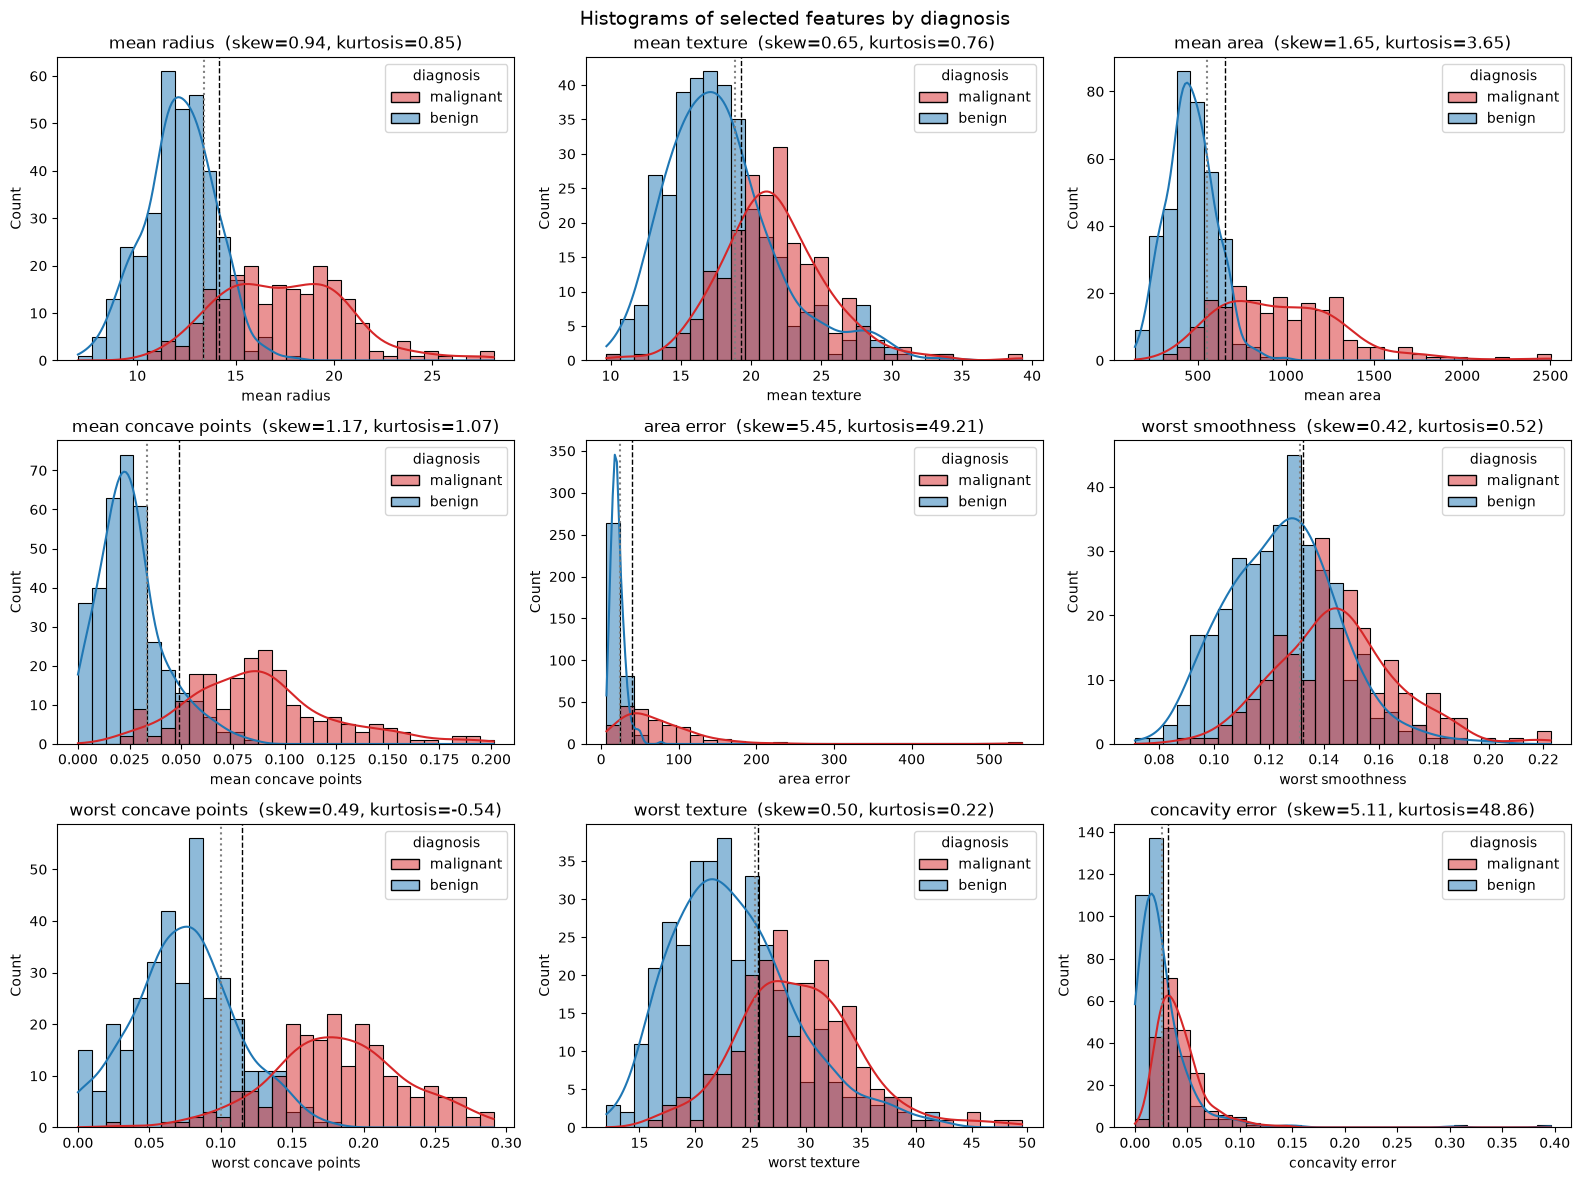

In [9]:
selected = ['mean radius', 'mean texture', 'mean area', 'mean concave points',
            'area error', 'worst smoothness', 'worst concave points', 'worst texture', 'concavity error']
df = X.assign(diagnosis=y.map(dict(enumerate(data.target_names))))

fig, axes = plt.subplots(3, 3, figsize=(16, 12))
for ax, col in zip(axes.flat, selected):
    sns.histplot(data=df, x=col, hue='diagnosis', bins=30, kde=True,
                 palette=palette, alpha=0.5, ax=ax)

    ax.axvline(X[col].mean(), color='black', ls='--', lw=1, label='mean')
    ax.axvline(X[col].median(), color='gray', ls=':', lw=1.5, label='median')
    ax.set_title(f"{col}  (skew={X[col].skew():.2f}, kurtosis={X[col].kurt():.2f})")
plt.suptitle('Histograms of selected features by diagnosis', fontsize=14)
plt.tight_layout()
plt.show()

**Key Observations:**

- All selected features are **right-skewed**, and the mean line lies to the right of the median. The effect is extreme for `area error` and `concavity error` (skewness about 5.4 and 5.1, kurtosis about 49). Most values sit close to the median, with a long tail reaching about 20 times the median (`area error` up to about 542, `concavity error` up to about 0.40). `worst concave points` is the exception: it is almost symmetric (skewness about 0.49) and flatter than a normal distribution (negative kurtosis).

- **The classes are clearly separated** for size and concavity features. Malignant tumors have a much larger `mean radius` (median about 17.3 vs 12.2), `mean area` (about 932 vs 458), `mean concave points` (about 0.086 vs 0.023) and `worst concave points` (about 0.182 vs 0.074). For the two `concave points` features the class distributions barely overlap, which makes them the strongest single predictors among the selected features.

- `mean texture`, `worst texture`, `worst smoothness` and `concavity error` separate the classes less well. Malignant values are shifted to the right, but the distributions overlap considerably. `worst texture` looks almost identical to `mean texture`, shifted to higher values (r about 0.91).

- For the size features, each class is more symmetric than the whole sample. Much of the overall skewness comes from **mixing two populations**: a narrow, compact benign group and a wider malignant group spread toward large values. This does not hold for the `error` features, which stay strongly skewed within each class.

- **Unexpected findings:**
  - The histogram of `worst concave points` has a small, isolated bar at its left edge (benign class). It is taller than the bar next to it (15 vs 7 samples), even though the rest of the distribution rises smoothly toward the middle. 13 of these 15 samples have a value of exactly **0**: these are small, smooth benign nuclei with no concave parts in their contour. The same 13 samples are also 0 in `mean concave points` and `concavity error`, but there the zeros fall into an already full first bin, so they are not visible as a separate peak.
  - An extremely long tail in `area error`, where a few malignant tumors have a standard error of area 10 times larger than typical.
  - The largest values of `concavity error` (up to about 0.40) belong to **benign** samples, even though malignant tumors are generally more concave.

- `mean radius` and `mean area` are almost perfectly correlated (r about 0.99) because they both measure size, so their histograms look nearly identical apart from scale. The `mean` and `worst` versions of the same measurement are also strongly correlated (r about 0.91 for both concave points and texture).

### e. Boxplots and violin plots

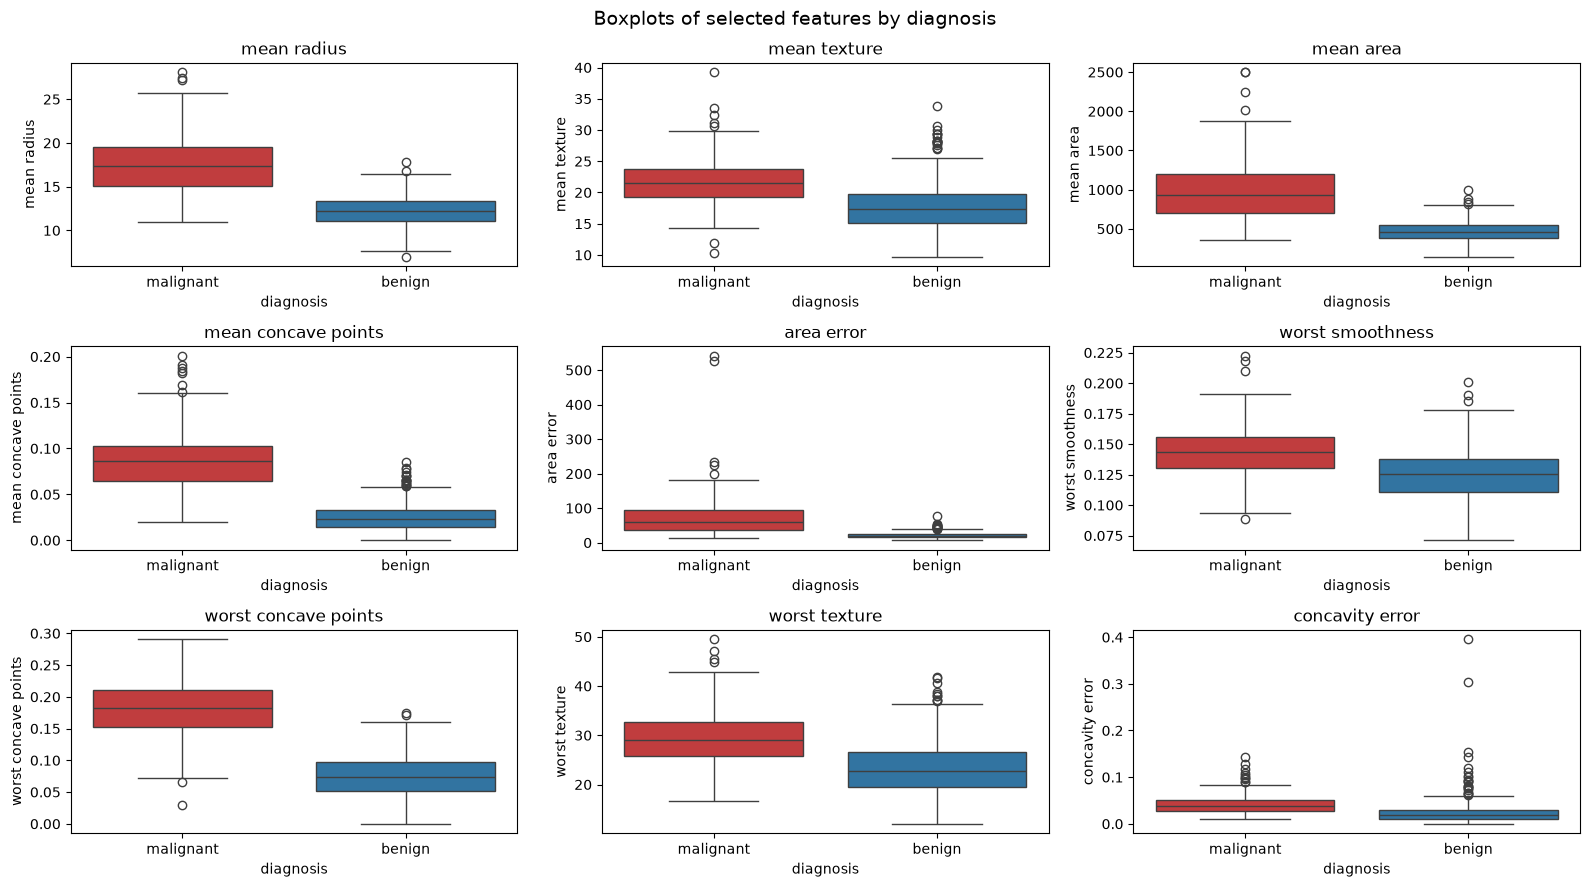

In [10]:
fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, selected):
    sns.boxplot(data=df, x='diagnosis', y=col, hue='diagnosis', palette=palette,
                order=['malignant', 'benign'], legend=False, ax=ax)
    ax.set_title(col)
plt.suptitle('Boxplots of selected features by diagnosis', fontsize=14)
plt.tight_layout()
plt.show()

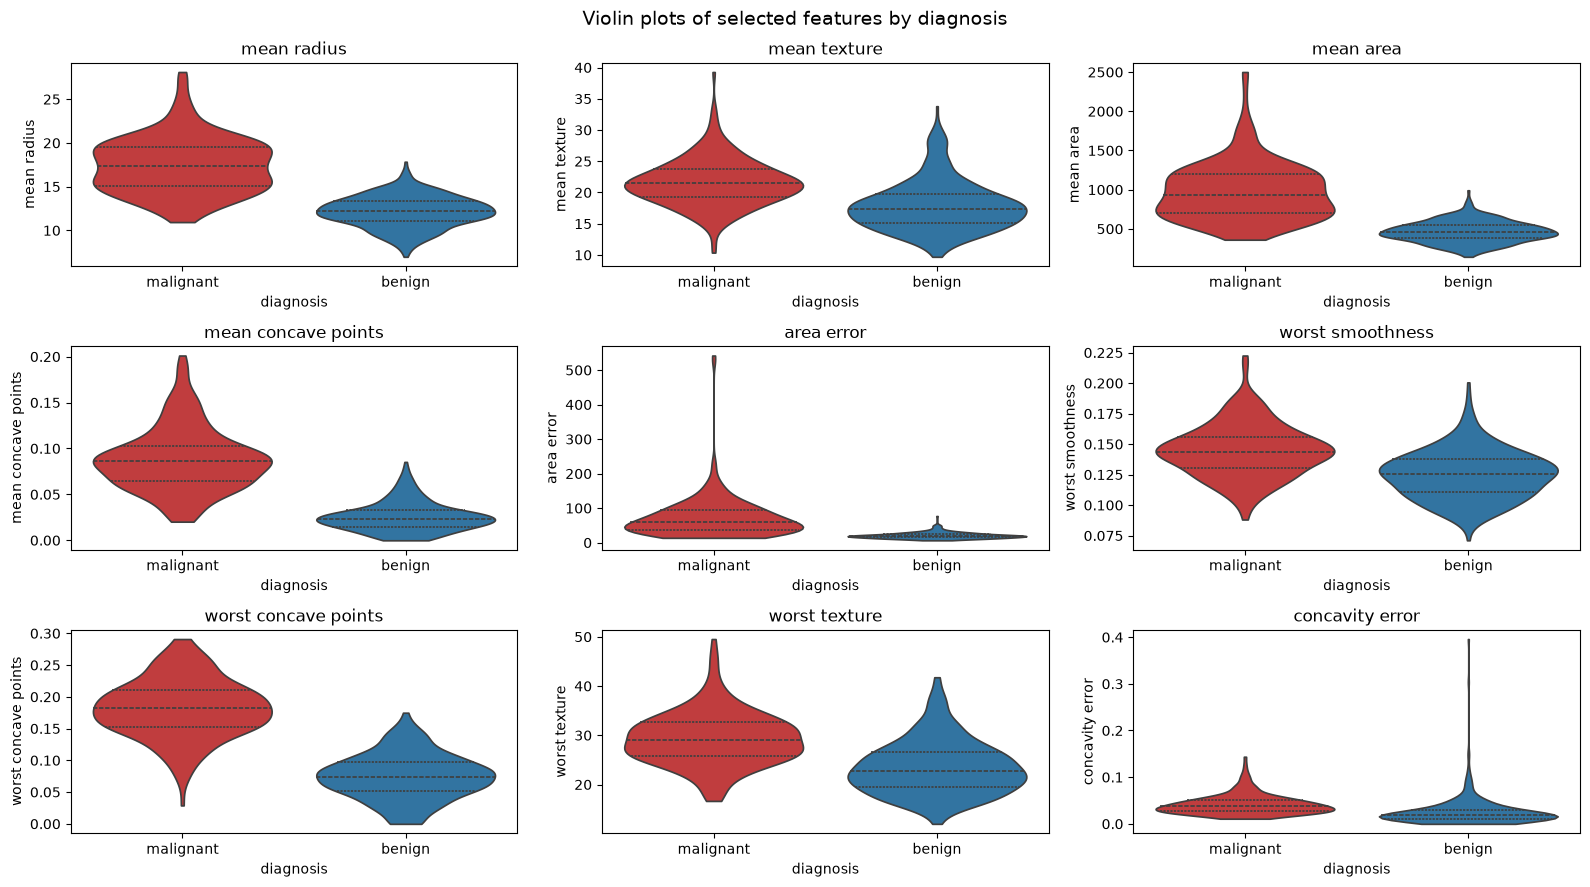

In [11]:
fig, axes = plt.subplots(3, 3, figsize=(16, 9))
for ax, col in zip(axes.flat, selected):
    sns.violinplot(data=df, x='diagnosis', y=col, hue='diagnosis', palette=palette,
                   order=['malignant', 'benign'], inner='quartile', cut=0, legend=False, ax=ax)
    ax.set_title(col)
plt.suptitle('Violin plots of selected features by diagnosis', fontsize=14)
plt.tight_layout()
plt.show()

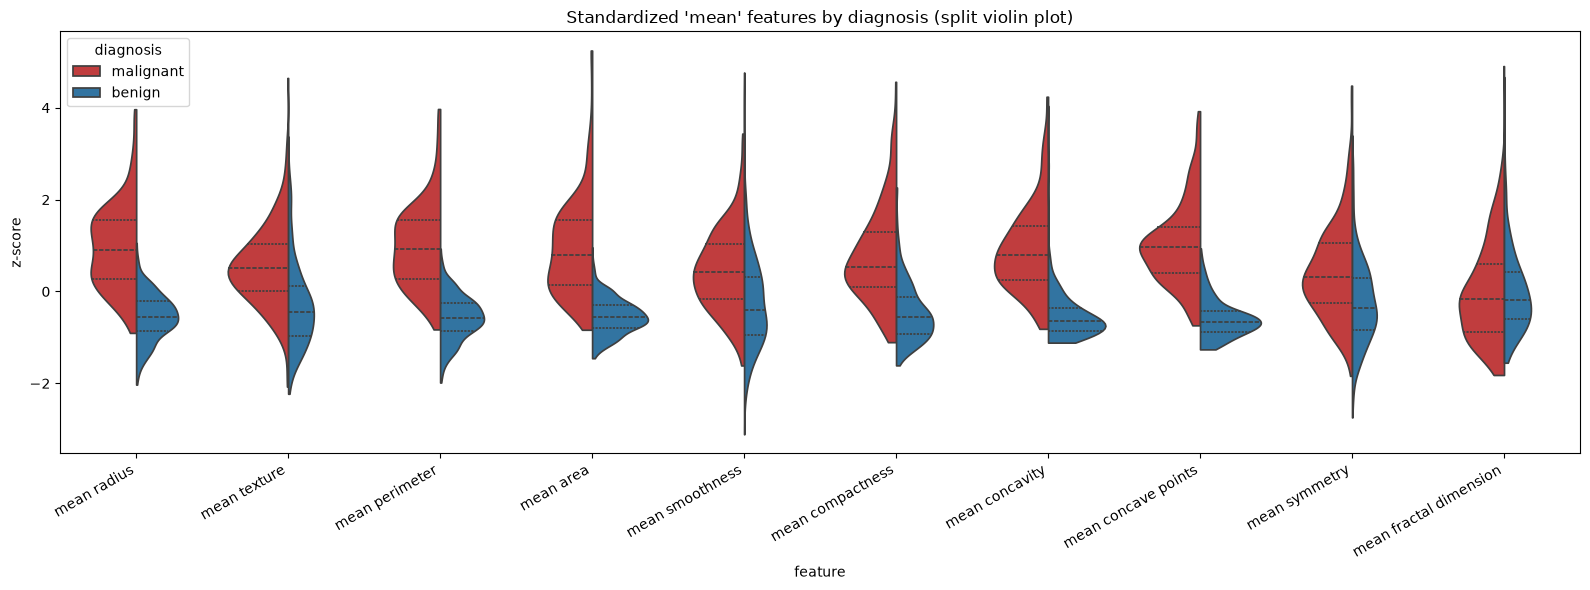

In [12]:
# Standardized view of all 'mean' features at once
mean_cols = [c for c in X.columns if c.startswith('mean')]
z_long = ((X[mean_cols] - X[mean_cols].mean()) / X[mean_cols].std()) \
    .assign(diagnosis=df['diagnosis']) \
    .melt(id_vars='diagnosis', var_name='feature', value_name='z-score')

plt.figure(figsize=(16, 6))
sns.violinplot(data=z_long, x='feature', y='z-score', hue='diagnosis', split=True,
               palette=palette, inner='quartile', cut=0)
plt.xticks(rotation=30, ha='right')
plt.title("Standardized 'mean' features by diagnosis (split violin plot)")
plt.tight_layout()
plt.show()

**Observations:**

- **Boxplots:** for `mean radius`, `mean area`, `mean concave points` and `worst concave points`, the boxes (IQRs) of the two classes **do not overlap at all**: the malignant Q1 lies above the benign Q3. For every selected feature the malignant median lies above the benign Q3. For the size and concavity features the malignant class also has a much larger spread (taller boxes and whiskers), so malignant tumors are more heterogeneous. For the texture features the spread is similar in both classes.

- Outlier points appear in **both classes**. For most features there are more of them in the benign class, mainly in `concavity error`, `mean texture`, `mean concave points` and `area error`. These are benign samples with unusually large values that resemble malignant cases, so they are likely to be hard to classify. The malignant class has fewer outliers, but they are far more extreme: the `area error` tail reaching about 542. `worst concave points` has almost no outliers in either class.

- **Violin plots** show the full shape of each distribution. Benign distributions are mostly narrow and unimodal, while malignant ones are wider with long upper tails. For `mean concave points` the benign violin is concentrated close to 0. `worst concave points` is close to symmetric in both classes. For `concavity error` the benign violin has a very long, thin upper tail, caused by the few extreme benign values.

- The **split violin plot of standardized features** shows that size and shape features (radius, perimeter, area, compactness, concavity, concave points) separate the classes strongly. `mean smoothness` and `mean symmetry` separate them moderately. **`mean fractal dimension` hardly differs between the classes**, so on its own it's a weak predictor.

- **Conclusion:** the data has a clear structure. Malignancy is linked to larger, more irregular, more concave nuclei. Several features are highly redundant (radius / perimeter / area, and the `mean` / `worst` pairs), and the strong class separation suggests that even simple models should reach high accuracy.

### f. Feature correlations

Correlation analysis shows how strongly the features are related to each other and to the target. Two coefficients are used:

- **Pearson correlation** $r$ measures the strength of a **linear** relationship, from -1 (perfect negative) through 0 (no linear relationship) to 1 (perfect positive). It is sensitive to outliers and skewed distributions.

- **Spearman correlation** $\rho$ is the Pearson correlation computed on **ranks** instead of raw values. It measures any **monotonic** relationship and is robust to outliers and skewness. The EDA showed that all features are right-skewed and contain outliers, so Spearman is a useful check.

Strongly correlated features (multicollinearity) carry largely the same information. This matters for interpretation, for linear models, and for the dimensionality reduction and feature selection steps in *Pipeline improvements*.

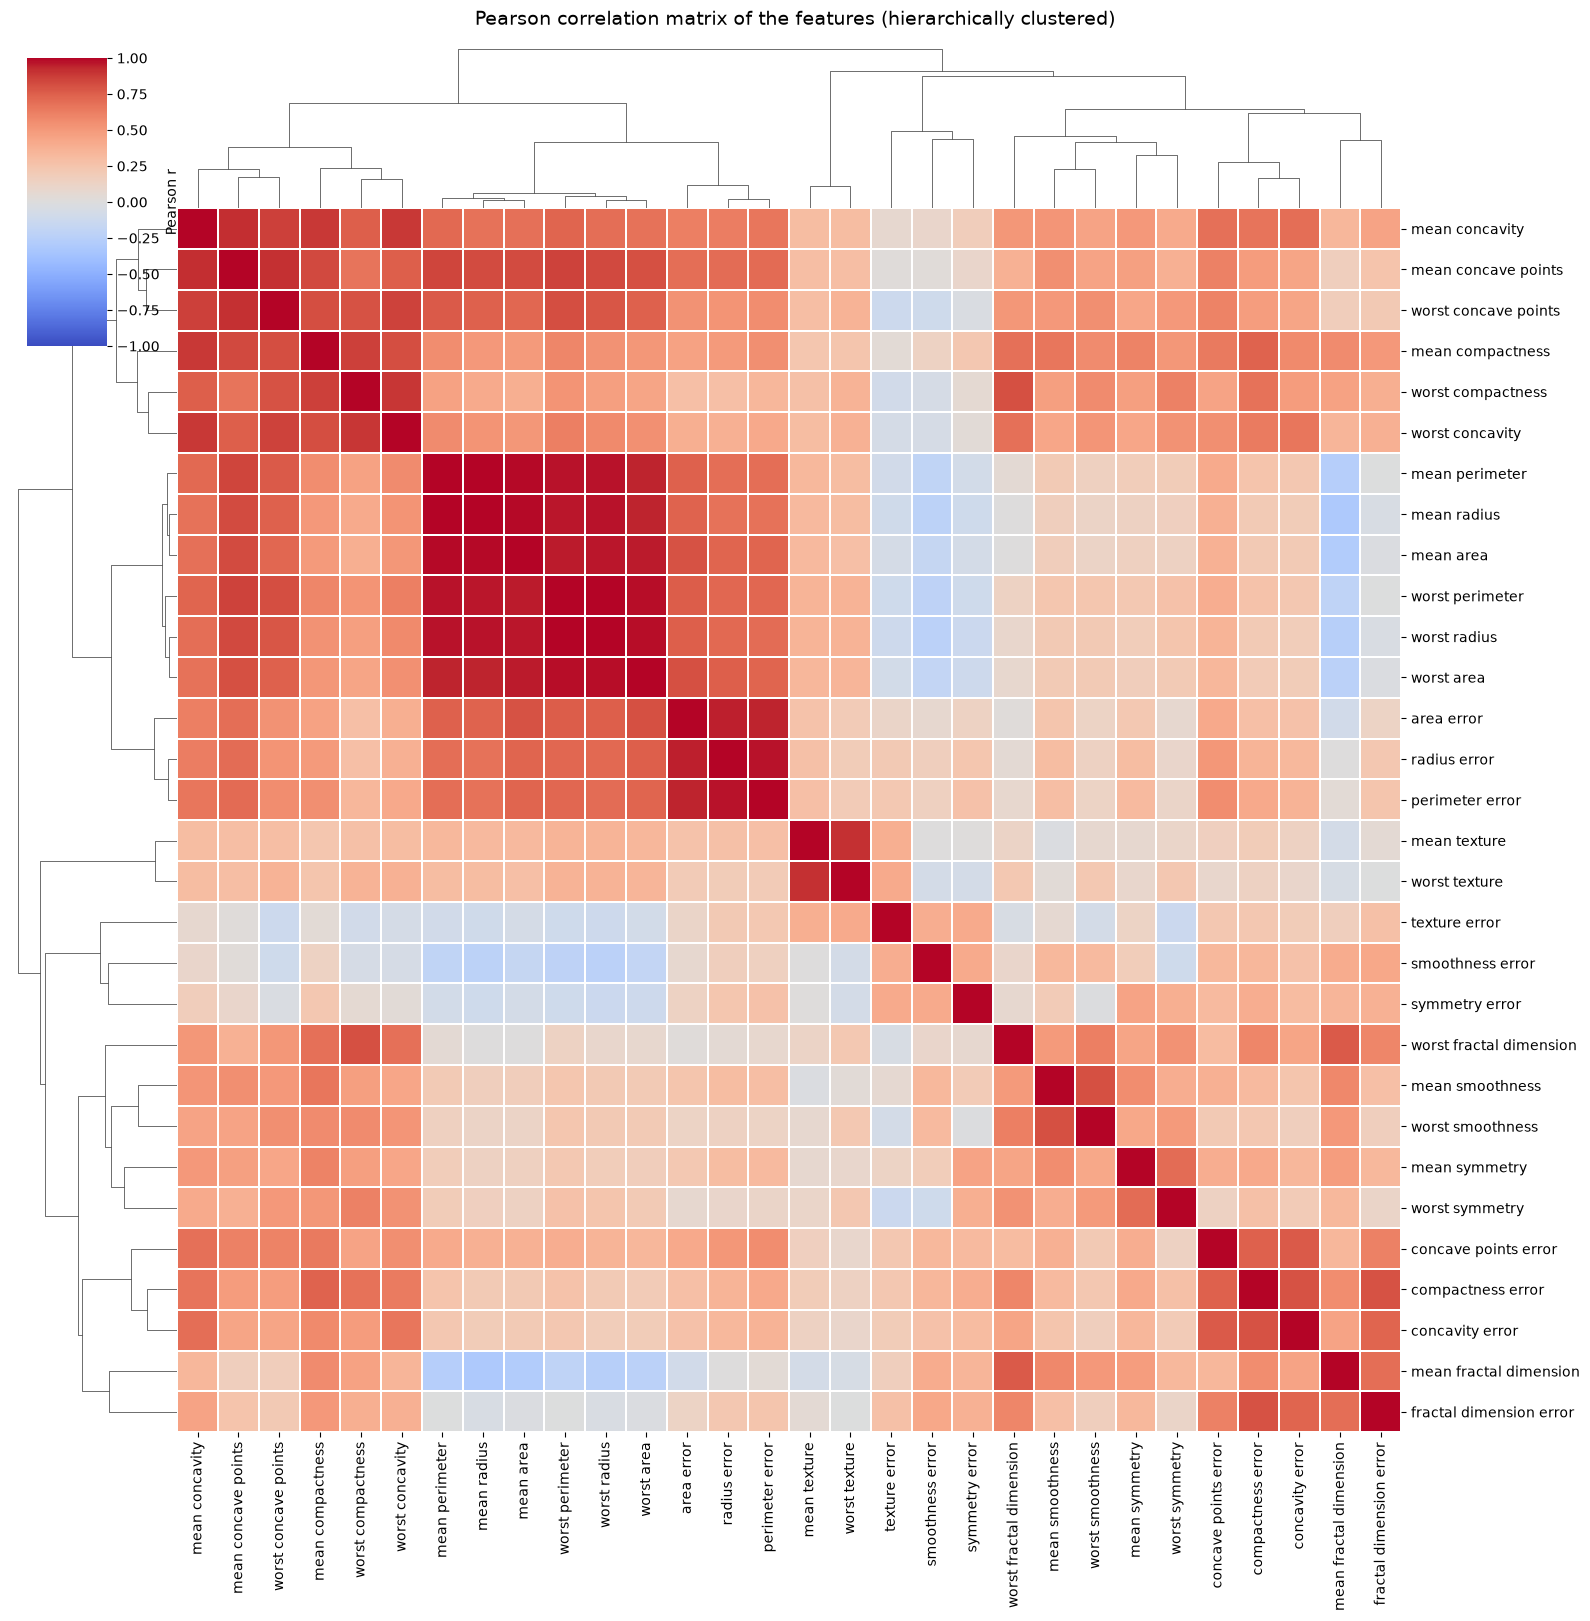

In [106]:
corr_pearson = X.corr(method='pearson')

cluster_grid = sns.clustermap(corr_pearson, method='average', cmap='coolwarm', vmin=-1, vmax=1,
                              center=0, figsize=(16, 16), linewidths=0.3,
                              cbar_kws={'label': 'Pearson r'}, dendrogram_ratio=0.12)
cluster_grid.figure.suptitle('Pearson correlation matrix of the features (hierarchically clustered)', fontsize=14, y=1.01)
plt.show()

In [107]:
upper_triangle = np.triu(np.ones(corr_pearson.shape, dtype=bool), k=1)
pairs = corr_pearson.where(upper_triangle).stack().dropna()

print(f'Feature pairs in total: {len(pairs)}')
for threshold in [0.9, 0.8, 0.7]:
    print(f'Pairs with |r| > {threshold}: {(pairs.abs() > threshold).sum()}')

strong_pairs = (pairs[pairs.abs() > 0.9].rename('Pearson r').to_frame()
                .assign(**{'Spearman rho': lambda d: [X[a].corr(X[b], method='spearman') for a, b in d.index]})
                .sort_values('Pearson r', ascending=False))
strong_pairs.index.names = ['feature 1', 'feature 2']
strong_pairs.round(3)

Feature pairs in total: 435
Pairs with |r| > 0.9: 21
Pairs with |r| > 0.8: 44
Pairs with |r| > 0.7: 70


,,Pearson r,Spearman rho
feature 1,feature 2,,
mean radius,mean perimeter,0.998,0.998
worst radius,worst perimeter,0.994,0.994
mean radius,mean area,0.987,1.000
mean perimeter,mean area,0.987,0.997
worst radius,worst area,0.984,0.999
worst perimeter,worst area,0.978,0.992
radius error,perimeter error,0.973,0.958
mean perimeter,worst perimeter,0.970,0.979
mean radius,worst radius,0.970,0.979


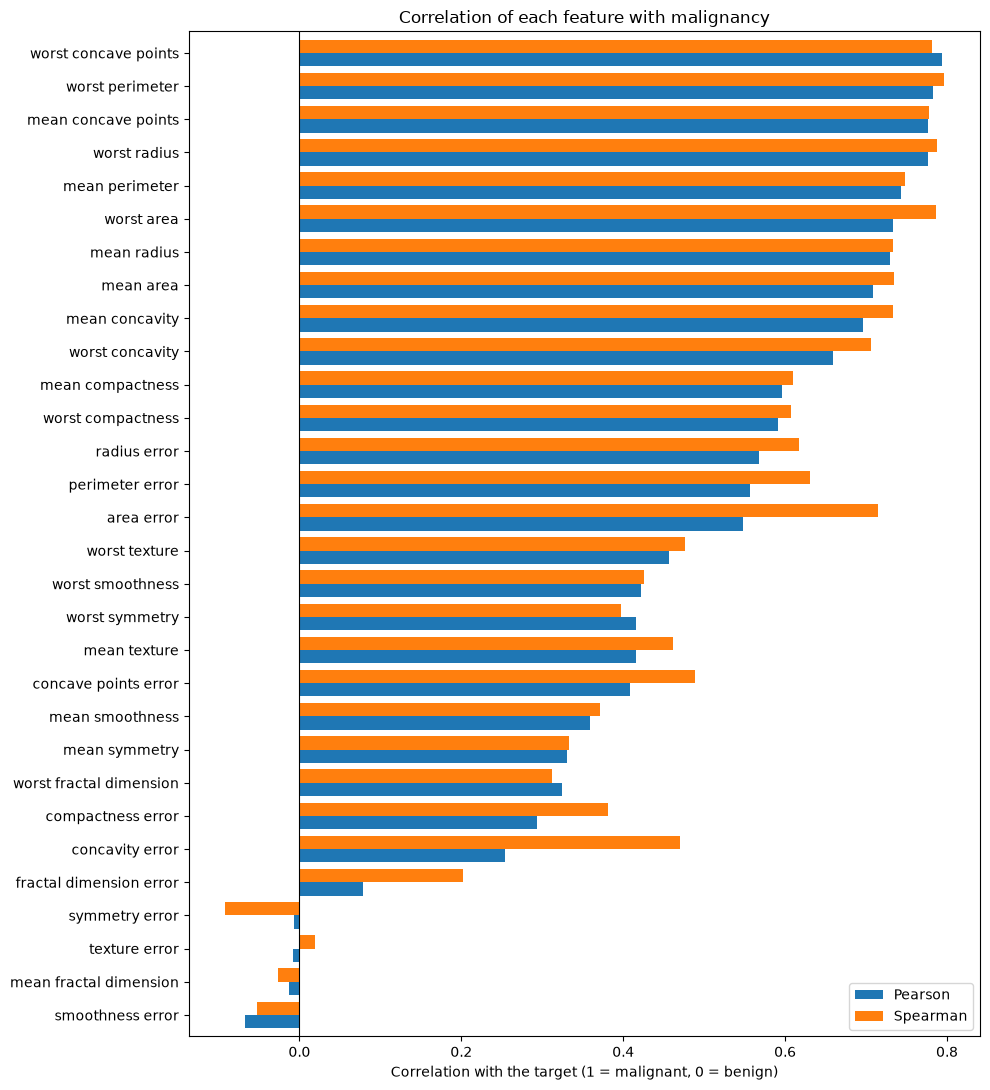

,Pearson,Spearman
worst concave points,0.794,0.782
worst perimeter,0.783,0.796
mean concave points,0.777,0.778
worst radius,0.776,0.788
mean perimeter,0.743,0.748
worst area,0.734,0.787
mean radius,0.730,0.733
mean area,0.709,0.734
mean concavity,0.696,0.733
worst concavity,0.660,0.706


In [108]:
is_malignant = (y == 0).astype(int)
target_corr = pd.DataFrame({
    'Pearson': X.corrwith(is_malignant, method='pearson'),
    'Spearman': X.corrwith(is_malignant, method='spearman'),
}).sort_values('Pearson')

ax = target_corr.plot.barh(figsize=(10, 11), width=0.8, color=['#1f77b4', '#ff7f0e'])
ax.axvline(0, color='black', lw=0.8)
ax.set_xlabel('Correlation with the target (1 = malignant, 0 = benign)')
ax.set_title('Correlation of each feature with malignancy')
plt.tight_layout()
plt.show()

target_corr.sort_values('Pearson', ascending=False).round(3)

**Observations:**

- **The features form clear groups of strongly correlated variables.** The clustered heatmap shows several distinct blocks:

  - **size**: `radius`, `perimeter` and `area` in the `mean` and `worst` variants. All pairs have $r > 0.94$, and `mean radius` vs `mean perimeter` reaches $r = 0.998$. This follows from geometry: perimeter ≈ $2\pi r$ and area ≈ $\pi r^2$, so these features measure the same property.

  - **size variability**: `radius error`, `perimeter error` and `area error` ($r$ = 0.94 to 0.97).

  - **shape irregularity**: `concavity`, `concave points` and `compactness` in the `mean` and `worst` variants.

  - **texture**: `mean texture` and `worst texture` ($r = 0.91$), almost unrelated to the other groups.

  - **smoothness, symmetry and fractal dimension**: weakly to moderately correlated with each other and with the rest.

- **The redundancy is large:** 21 of 435 feature pairs have $|r| > 0.9$, 44 have $|r| > 0.8$ and 70 have $|r| > 0.7$. The `mean` and `worst` versions of the same measurement are also strongly correlated (e.g. $r = 0.97$ for radius and perimeter). The 30 features therefore carry much less independent information than their number suggests. This explains why PCA needs only 10 components to keep 95% of the variance, and why univariate feature selection picks almost only size features (see *Pipeline improvements*).

- **Negative correlations are weak.** The strongest one is between `mean radius` and `mean fractal dimension` ($r = -0.31$): larger nuclei tend to have slightly smoother, less "fractal" contours.

- **Correlation with the target:**

  - The features most correlated with malignancy are `worst concave points` (0.79), `worst perimeter`, `mean concave points` and `worst radius` (about 0.78), followed by the other size features. This agrees with the histograms and boxplots, where these features separated the classes best.

  - `texture`, `smoothness` and `symmetry` are only moderately correlated with the target (0.33 to 0.46).

  - `mean fractal dimension`, `texture error`, `symmetry error` and `smoothness error` have practically **no correlation** with the target ($|r| \le 0.07$), which confirms the observation from the split violin plot.

- **Pearson vs Spearman:**

  - For most features the two coefficients are almost identical, so the relationships are close to linear.

  - The largest differences appear for the strongly skewed `error` features: for example `area error` (Pearson 0.55 vs Spearman 0.71) and `concavity error` (0.25 vs 0.47). Their extreme outliers weaken the linear correlation, while the rank-based Spearman shows a stronger monotonic relationship. This is another argument for a log transform of these features in linear models.

**Implications for modelling:**

- Gradient boosting models are not affected by multicollinearity in terms of predictive quality, because each split uses one feature at a time. However, their **feature importances are split among correlated features**, so the importance of a single feature should be interpreted with care.

- For **linear models**, strong multicollinearity makes the coefficients unstable and hard to interpret. Regularization, PCA or removing redundant features helps.

- The groups above are natural candidates for **dimensionality reduction**: much of the information in the 30 features can be represented by far fewer variables.

## **Data processing and Model Application**

### Train/test split

The dataset is split into a **training set (80%, 455 samples)** and a **test set (20%, 114 samples)**. The test set is used only for the final evaluation, so it gives an estimate of how the models perform on unseen data.

- `stratify=y` keeps the class proportions (about 63% benign / 37% malignant) the same in both sets. This matters because the classes are imbalanced and the test set is small.

- `random_state=42` makes the split reproducible.

- All preprocessing steps are fitted on the training set only, inside the pipeline. This prevents **data leakage**: no information about the test set (e.g. its mean or variance) influences the model.

In [ ]:
train_X, test_X, train_y, test_y = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

### Pipeline design

Both models use the same preprocessing, defined in `build_baseline_pipeline()`. This way the comparison between XGBoost and CatBoost is fair: the only difference is the classifier. The pipeline consists of:

1. **`VarianceThreshold(threshold=0.0)`** removes constant features (zero variance), which carry no information. It is placed *before* the scaler, because after standardization every feature has variance equal to 1 and a variance-based filter would no longer be meaningful. The dataset has no constant features, so nothing is removed here. The step acts as a safeguard for new data in production.

2. **`StandardScaler`** standardizes each feature to zero mean and unit variance. As shown in the EDA, the features are on very different scales (e.g. `worst area` up to about 4254 vs `fractal dimension error` below 0.03). Tree-based models are insensitive to monotonic transformations, so scaling isn't strictly needed for them. It is kept to make the pipeline ready for scale-sensitive steps such as PCA (see *Pipeline improvements*).

3. **Classifier**, either XGBoost or CatBoost.

No other preprocessing is needed: there are no missing values, no categorical features and no duplicates. Outliers are kept on purpose: they mostly represent real, malignant cases, and gradient boosting models are robust to them.

**Models and hyperparameters.** Both are gradient boosting ensembles of decision trees, trained with similar, moderate settings to keep the comparison fair and to limit overfitting on this small dataset:

- **XGBoost:** 100 trees, `max_depth=3`, `learning_rate=0.1`, with row and column subsampling (`subsample=0.8`, `colsample_bytree=0.8`) as additional regularization.

- **CatBoost:** 100 iterations, `depth=3`, `learning_rate=0.1`. CatBoost builds *symmetric (oblivious)* trees, in which every node at a given depth uses the same split. This acts as a form of regularization and often makes CatBoost work well with default settings.

In [81]:
def build_baseline_pipeline(classifier):
    return Pipeline([
        ('variance_threshold', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('classifier', classifier)
    ])

In [82]:
xgb = XGBClassifier(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8, random_state=42, eval_metric='logloss')
catboost = CatBoostClassifier(iterations=100, depth=3, learning_rate=0.1, random_state=42, verbose=0)

cancer_xgb_baseline_pipeline = build_baseline_pipeline(xgb)
cancer_catboost_baseline_pipeline = build_baseline_pipeline(catboost)

### Model training

Each pipeline is fitted on the training data only. When `fit()` is called, every step is fitted in turn and transforms the data for the next one: `VarianceThreshold` learns the feature variances, `StandardScaler` learns the mean and standard deviation of each feature, and the classifier is trained on the transformed data. The same fitted transformations are later applied to the test data in `predict()`.

#### a. XGBoost model

In [83]:
cancer_xgb_baseline_pipeline.fit(train_X, train_y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance_threshold', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"


#### b. Catboost model

In [84]:
cancer_catboost_baseline_pipeline.fit(train_X, train_y)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('variance_threshold', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"threshold threshold: float, default=0Features with a training-set variance lower than this threshold willbe removed. The default is to keep all features with non-zero variance,i.e. remove the features that have the same value in all samples.",0.0
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"


## **Quality of the model**

The fitted pipelines are applied to the test set, which the models have not seen during training. The following metrics are reported for each class:

- **Accuracy**: the share of all correctly classified samples.

- **Precision**: of the samples predicted as a given class, how many truly belong to it.

- **Recall (sensitivity)**: of the samples that truly belong to a given class, how many were detected. For the **malignant** class this is the key metric, because a missed malignant tumor (false negative) is far more dangerous than a false alarm.

- **F1-score**: the harmonic mean of precision and recall.

- **ROC AUC**: the area under the ROC curve, computed from the predicted probabilities. It shows how well the model separates the classes regardless of the decision threshold.

- **Confusion matrix**: the number of correct and incorrect predictions for each class.

Note: in this dataset `0 = malignant` and `1 = benign`. Scikit-learn metrics treat `1` as the positive class by default, so per-class results are taken from `classification_report` (or computed with `pos_label=0`).

#### a. XGBoost model

In [85]:
y_pred = cancer_xgb_baseline_pipeline.predict(test_X)
print(classification_report(test_y, y_pred, target_names=data.target_names, digits=4))

              precision    recall  f1-score   support

   malignant     0.9512    0.9286    0.9398        42
      benign     0.9589    0.9722    0.9655        72

    accuracy                         0.9561       114
   macro avg     0.9551    0.9504    0.9526       114
weighted avg     0.9561    0.9561    0.9560       114



**Observations (XGBoost):**
- The model reaches **95.6% accuracy** on the test set: 109 of 114 samples are classified correctly.

- **3 of 42 malignant tumors are missed** (recall for malignant = 92.9%) and 2 of 72 benign tumors are wrongly flagged as malignant (recall for benign = 97.2%).

- In a medical setting the missed malignant cases (false negatives) are the most costly errors, so **recall for the malignant class** is the most important metric here. Lowering the decision threshold could reduce these errors at the cost of more false alarms.

- With only 114 test samples, a single misclassification changes accuracy by about 0.9 percentage points, so small differences between models should be interpreted with caution.

#### b. Catboost model

In [86]:
y_pred_catboost = cancer_catboost_baseline_pipeline.predict(test_X)
print(classification_report(test_y, y_pred_catboost, target_names=data.target_names, digits=4))

              precision    recall  f1-score   support

   malignant     0.9750    0.9286    0.9512        42
      benign     0.9595    0.9861    0.9726        72

    accuracy                         0.9649       114
   macro avg     0.9672    0.9573    0.9619       114
weighted avg     0.9652    0.9649    0.9647       114



**Observations (CatBoost):**
- The model reaches **96.5% accuracy** on the test set: 110 of 114 samples are classified correctly.

- Like XGBoost, it **misses 3 of 42 malignant tumors** (recall for malignant = 92.9%). It makes only one false alarm: 1 of 72 benign tumors is flagged as malignant (recall for benign = 98.6%).

- As a result, its precision for the malignant class is higher (97.5% vs 95.1% for XGBoost): almost every sample it predicts as malignant really is malignant.

#### c. Comparison of the models on the test set

The two models are compared on the same test set using:

- the metrics above: accuracy, plus precision, recall and F1-score for the **malignant** class (`pos_label=0`),

- **ROC AUC**, which is computed from the predicted probabilities rather than hard labels. It measures how well the model ranks malignant cases above benign ones across all possible decision thresholds (1.0 = perfect, 0.5 = random),

- **confusion matrices**, which show exactly how many samples of each class were misclassified,

- **ROC curves**, which show the trade-off between the true positive rate and the false positive rate for every threshold.

In [ ]:
models = {
    'XGBoost': cancer_xgb_baseline_pipeline,
    'CatBoost': cancer_catboost_baseline_pipeline,
}

def evaluate(pipeline, X_test, y_test):
    y_pred = pipeline.predict(X_test)
    y_proba_malignant = pipeline.predict_proba(X_test)[:, 0]   # column 0 = malignant
    return {
        'accuracy': accuracy_score(y_test, y_pred),
        'precision (malignant)': precision_score(y_test, y_pred, pos_label=0),
        'recall (malignant)': recall_score(y_test, y_pred, pos_label=0),
        'F1 (malignant)': f1_score(y_test, y_pred, pos_label=0),
        'recall (benign)': recall_score(y_test, y_pred, pos_label=1),
        'ROC AUC': roc_auc_score(y_test == 0, y_proba_malignant),
        'errors': int((y_pred != y_test).sum()),
    }

test_results = pd.DataFrame({name: evaluate(p, test_X, test_y) for name, p in models.items()}).T
test_results.round(4)

,accuracy,precision (malignant),recall (malignant),F1 (malignant),recall (benign),ROC AUC,errors
XGBoost,0.9561,0.9512,0.9286,0.9398,0.9722,0.9940,5.0
CatBoost,0.9649,0.9750,0.9286,0.9512,0.9861,0.9937,4.0


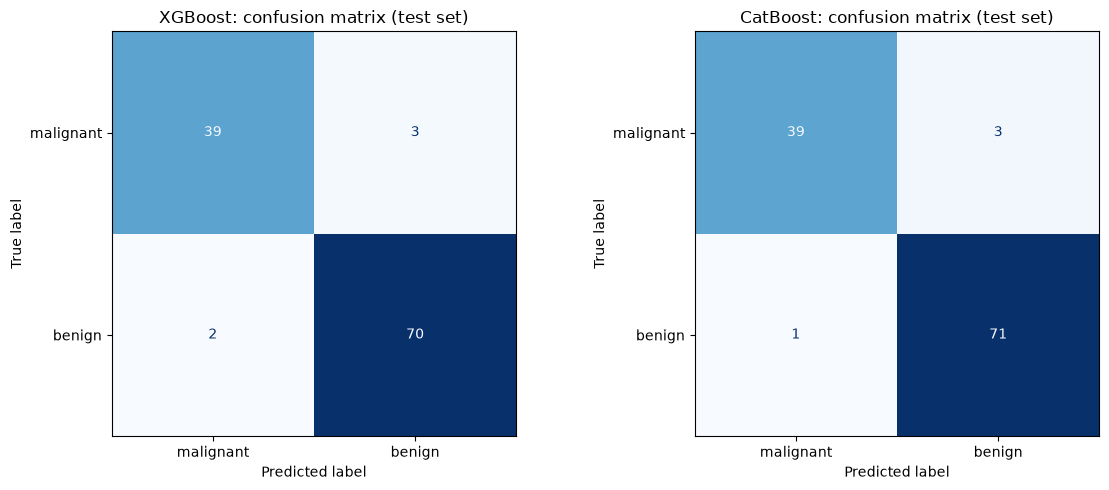

In [88]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, pipeline) in zip(axes, models.items()):
    ConfusionMatrixDisplay.from_estimator(
        pipeline, test_X, test_y, display_labels=data.target_names, cmap='Blues', colorbar=False, ax=ax
    )
    ax.set_title(f'{name}: confusion matrix (test set)')
plt.tight_layout()
plt.show()

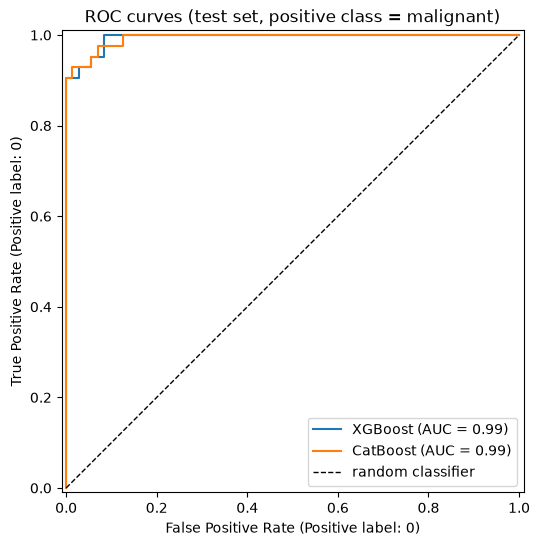

In [89]:
fig, ax = plt.subplots(figsize=(7, 6))
for name, pipeline in models.items():
    RocCurveDisplay.from_estimator(pipeline, test_X, test_y, pos_label=0, name=name, ax=ax)
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='random classifier')
ax.set_title('ROC curves (test set, positive class = malignant)')
ax.legend(loc='lower right')
plt.show()

**Observations (test set):**

- **CatBoost is slightly better on the test set**: 96.5% vs 95.6% accuracy and 97.5% vs 95.1% precision for the malignant class. The whole difference comes from **a single sample**: CatBoost makes 4 errors, XGBoost 5.

- Both models have **the same recall for the malignant class (92.9%)**: each misses 3 of 42 malignant tumors. For the most important metric there is no difference between them.

- **ROC AUC is practically the same** (0.994 for both). Both models rank malignant cases above benign ones almost perfectly, and their ROC curves nearly overlap. Because AUC is close to 1, a different decision threshold could reduce the number of missed malignant tumors at the cost of a few more false alarms.

- Both confusion matrices show that the dominant error type is the **false negative** (malignant predicted as benign), which is the more dangerous one in a medical setting.

#### d. Cross-validation on the training set

The test set contains only 114 samples, so a single misclassification changes accuracy by about 0.9 percentage points. A difference of one or two samples between the models may therefore be due to chance, i.e. to the particular train/test split.

To get a more reliable comparison, both pipelines are additionally evaluated with **stratified 5-fold cross-validation on the training set**. The training data is split into 5 folds that keep the class proportions. Each model is trained 5 times, each time on 4 folds, and evaluated on the remaining one. Both models use **the same folds**, so the comparison is fair. The whole pipeline is passed to cross-validation, so `VarianceThreshold` and `StandardScaler` are fitted separately in each fold and no information leaks from the validation fold. The test set is not used here at all.

In [ ]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    'accuracy': 'accuracy',
    'recall (malignant)': make_scorer(recall_score, pos_label=0),
    'F1 (malignant)': make_scorer(f1_score, pos_label=0),
    'ROC AUC': 'roc_auc',
}

cv_results = {}
for name, pipeline in models.items():
    scores = cross_validate(pipeline, train_X, train_y, cv=cv, scoring=scoring)
    cv_results[name] = {
        f'{metric} ({stat})': func(scores[f'test_{metric}'])
        for metric in scoring for stat, func in [('mean', np.mean), ('std', np.std)]
    }

cv_results = pd.DataFrame(cv_results).T
cv_results.round(4)

,accuracy (mean),accuracy (std),recall (malignant) (mean),recall (malignant) (std),F1 (malignant) (mean),F1 (malignant) (std),ROC AUC (mean),ROC AUC (std)
XGBoost,0.9648,0.0146,0.9529,0.0235,0.9532,0.0189,0.9943,0.0038
CatBoost,0.9714,0.0132,0.9529,0.0144,0.9616,0.0170,0.9922,0.0058


**Observations (cross-validation):**

- Cross-validation confirms the test-set results: both models are very accurate and close to each other. **CatBoost reaches 97.1% ± 1.3% accuracy and XGBoost 96.5% ± 1.5%.**

- The difference in mean accuracy (about 0.7 pp) is **smaller than the standard deviation between folds**, so it isn't significant. On a different split of the data the order of the models could easily reverse.

- **Recall for the malignant class is identical (95.3%)** for both models, and ROC AUC is very high for both (0.994 for XGBoost, 0.992 for CatBoost). CatBoost has a slightly higher F1 for the malignant class and a lower fold-to-fold variance of recall, so it is a little more stable.

- The cross-validation scores are slightly higher than the test-set scores (e.g. recall for malignant 95.3% vs 92.9%). This is expected, because the test-set result relies on only 42 malignant samples, where each missed case lowers recall by about 2.4 pp.

**Conclusion:** both gradient boosting pipelines perform very well on this dataset (about 96 to 97% accuracy, ROC AUC above 0.99). **CatBoost is marginally better** on the test set and in cross-validation, mainly because it raises fewer false alarms. The difference is within the statistical noise, though, and both models miss the same share of malignant tumors. In practice the two models are equivalent here. The more promising direction is improving recall for the malignant class, e.g. by tuning the decision threshold or the hyperparameters (see *Pipeline improvements*).

## **Pipeline improvements**

In this section the baseline pipeline is extended step by step and each change is checked separately:

- a. Does `StandardScaler` affect the quality of the gradient boosting models?

- b. Dimensionality reduction with PCA.

- c. Feature selection.

- d. Hyperparameter tuning of the whole pipeline with `GridSearchCV`.

- e. Tuning the decision threshold to reduce the number of missed malignant tumors.

- f. Final comparison with the baseline on the test set.

- g. What else should be done before deploying the models to production.

All comparisons (a to e) use **only the training set**, with **repeated stratified 5-fold cross-validation** (5 folds × 3 repeats = 15 evaluations per variant) and the same folds for every variant. The test set is used **once**, in section f, to evaluate the final pipelines. Choosing a variant based on test-set results would overfit to the test set.

In [93]:
cv_repeated = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=RANDOM_STATE)


def make_xgb(**params):
    defaults = dict(n_estimators=100, max_depth=3, learning_rate=0.1, subsample=0.8,
                    colsample_bytree=0.8, random_state=RANDOM_STATE, eval_metric='logloss')
    return XGBClassifier(**{**defaults, **params})


def make_catboost(**params):
    defaults = dict(iterations=100, depth=3, learning_rate=0.1, random_state=RANDOM_STATE,
                    verbose=0, allow_writing_files=False)
    return CatBoostClassifier(**{**defaults, **params})


def cv_compare(pipelines, X_train, y_train, cv=cv_repeated):
    """Cross-validates each pipeline on the same folds and returns mean ± std of the metrics."""
    rows = {}
    for name, pipeline in pipelines.items():
        scores = cross_validate(pipeline, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
        row = {}
        for metric in scoring:
            values = scores[f'test_{metric}']
            row[metric] = f'{values.mean():.4f} ± {values.std():.4f}'
        rows[name] = row
    return pd.DataFrame(rows).T

### a. Does `StandardScaler` affect the quality of the gradient boosting models?

Both models are cross-validated with the baseline pipeline (with `StandardScaler`) and with the same pipeline without the scaler.

In [94]:
def build_pipeline_without_scaler(classifier):
    return Pipeline([
        ('variance_threshold', VarianceThreshold(threshold=0.0)),
        ('classifier', classifier),
    ])

scaler_comparison = cv_compare({
    'XGBoost + scaler': build_baseline_pipeline(make_xgb()),
    'XGBoost, no scaler': build_pipeline_without_scaler(make_xgb()),
    'CatBoost + scaler': build_baseline_pipeline(make_catboost()),
    'CatBoost, no scaler': build_pipeline_without_scaler(make_catboost()),
}, train_X, train_y)
scaler_comparison

,accuracy,recall (malignant),F1 (malignant),ROC AUC
XGBoost + scaler,0.9663 ± 0.0158,0.9510 ± 0.0334,0.9547 ± 0.0212,0.9941 ± 0.0057
"XGBoost, no scaler",0.9663 ± 0.0158,0.9510 ± 0.0334,0.9547 ± 0.0212,0.9941 ± 0.0057
CatBoost + scaler,0.9714 ± 0.0174,0.9529 ± 0.0369,0.9613 ± 0.0238,0.9932 ± 0.0063
"CatBoost, no scaler",0.9714 ± 0.0174,0.9529 ± 0.0369,0.9613 ± 0.0238,0.9932 ± 0.0063


**Answer: no. `StandardScaler` has no effect on the gradient boosting models.** With and without the scaler, both XGBoost and CatBoost give **exactly the same results** in every fold (e.g. XGBoost 0.9663 ± 0.0158 accuracy in both cases).

This is expected. Gradient boosting builds decision trees, and each split has the form `feature <= threshold`. Standardization is a monotonic (order-preserving) transformation: it changes the values of a feature but not their order. Every split that is possible on the raw data has an exact equivalent on the scaled data (only the threshold value changes), so the trees and their predictions are identical.

Scaling *does* matter for methods based on distances, gradients or variance, such as logistic regression, SVM, k-NN, neural networks and **PCA**. That is why the scaler stays in the pipeline: it is needed for the PCA step below and for the logistic regression used as a reference.

### b. Dimensionality reduction with PCA

**Principal Component Analysis (PCA)** replaces the 30 original features with a smaller number of uncorrelated *principal components*, which are linear combinations of the original features ordered by the amount of variance they explain. The EDA showed that many features are strongly correlated (e.g. radius / perimeter / area, and the `mean` / `worst` pairs), so a large part of the information should fit in a few components.

PCA is added to the pipeline **after `StandardScaler`**. PCA is driven by variance, so without scaling the components would be dominated by features with large values such as `worst area`. This is the step where the scaler really matters. The number of components can be given directly (e.g. `n_components=10`) or as the share of variance to keep (e.g. `n_components=0.95`).

90% of variance is explained by 7 components
95% of variance is explained by 10 components
99% of variance is explained by 17 components


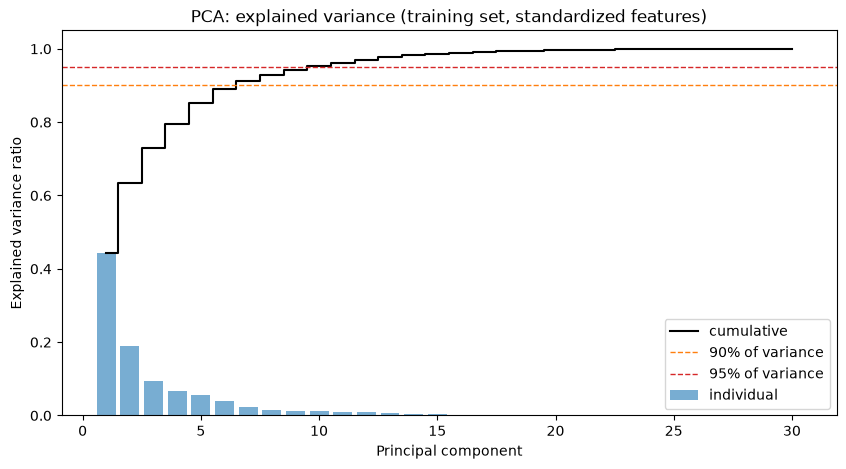

In [95]:
pca_full = Pipeline([('scaler', StandardScaler()), ('pca', PCA())]).fit(train_X)['pca']
cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_)

for threshold in [0.90, 0.95, 0.99]:
    n = np.searchsorted(cumulative_variance, threshold) + 1
    print(f'{threshold:.0%} of variance is explained by {n} components')

fig, ax = plt.subplots(figsize=(10, 5))
components = np.arange(1, len(cumulative_variance) + 1)
ax.bar(components, pca_full.explained_variance_ratio_, alpha=0.6, label='individual')
ax.step(components, cumulative_variance, where='mid', color='black', label='cumulative')
for threshold, color in [(0.90, 'tab:orange'), (0.95, 'tab:red')]:
    ax.axhline(threshold, color=color, ls='--', lw=1, label=f'{threshold:.0%} of variance')
ax.set_xlabel('Principal component')
ax.set_ylabel('Explained variance ratio')
ax.set_title('PCA: explained variance (training set, standardized features)')
ax.legend()
plt.show()

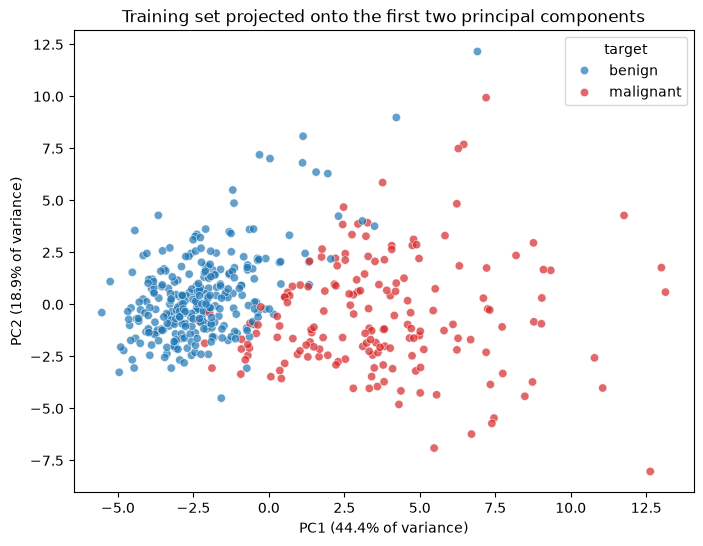

In [96]:
pca_2d = Pipeline([('scaler', StandardScaler()), ('pca', PCA(n_components=2))]).fit(train_X)
train_pca_2d = pca_2d.transform(train_X)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=train_pca_2d[:, 0], y=train_pca_2d[:, 1], alpha=0.7,
                hue=train_y.map(dict(enumerate(data.target_names))), palette=palette)
ratio = pca_2d['pca'].explained_variance_ratio_
plt.xlabel(f'PC1 ({ratio[0]:.1%} of variance)')
plt.ylabel(f'PC2 ({ratio[1]:.1%} of variance)')
plt.title('Training set projected onto the first two principal components')
plt.show()

In [97]:
def build_pca_pipeline(classifier, n_components):
    return Pipeline([
        ('variance_threshold', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=n_components, random_state=RANDOM_STATE)),
        ('classifier', classifier),
    ])

pca_comparison = cv_compare({
    'XGBoost (no PCA)': build_baseline_pipeline(make_xgb()),
    'XGBoost + PCA (90%)': build_pca_pipeline(make_xgb(), 0.90),
    'XGBoost + PCA (95%)': build_pca_pipeline(make_xgb(), 0.95),
    'CatBoost (no PCA)': build_baseline_pipeline(make_catboost()),
    'CatBoost + PCA (90%)': build_pca_pipeline(make_catboost(), 0.90),
    'CatBoost + PCA (95%)': build_pca_pipeline(make_catboost(), 0.95),
}, train_X, train_y)
pca_comparison

,accuracy,recall (malignant),F1 (malignant),ROC AUC
XGBoost (no PCA),0.9663 ± 0.0158,0.9510 ± 0.0334,0.9547 ± 0.0212,0.9941 ± 0.0057
XGBoost + PCA (90%),0.9626 ± 0.0179,0.9373 ± 0.0354,0.9493 ± 0.0242,0.9906 ± 0.0076
XGBoost + PCA (95%),0.9604 ± 0.0154,0.9373 ± 0.0370,0.9464 ± 0.0210,0.9912 ± 0.0074
CatBoost (no PCA),0.9714 ± 0.0174,0.9529 ± 0.0369,0.9613 ± 0.0238,0.9932 ± 0.0063
CatBoost + PCA (90%),0.9590 ± 0.0225,0.9275 ± 0.0414,0.9439 ± 0.0311,0.9889 ± 0.0102
CatBoost + PCA (95%),0.9575 ± 0.0223,0.9275 ± 0.0354,0.9421 ± 0.0306,0.9882 ± 0.0104


**Observations:**
- Thanks to the strong correlations between features, **7 components explain 90% and 10 components explain 95% of the variance** (out of 30 features). The first component alone explains about 44%. It mostly captures the "size and concavity" of the nucleus, which is exactly the direction that separates the classes.

- The 2D projection shows that **the classes are already well separated along the first principal component**: benign samples form a compact cluster, malignant ones spread out to one side. Only a narrow overlap zone remains.

- Despite this, **PCA slightly lowers the quality of both boosting models**. XGBoost loses about 0.4 to 0.6 pp of accuracy and CatBoost about 1.2 to 1.4 pp. Recall for the malignant class drops by 1.4 to 2.5 pp.

- The reason: decision trees split on one feature at a time, and they choose the useful original features on their own. PCA replaces them with linear combinations that are harder to split with axis-aligned thresholds, and the components are chosen by variance, not by how well they separate the classes. Some discriminative information is lost in the discarded components.

**Conclusion:** extending the pipeline with PCA is simple. Add `PCA(n_components=...)` after `StandardScaler` and treat `n_components` as a hyperparameter. For tree-based models on this dataset it doesn't improve the predictions. Its benefits here would be a smaller input, removed multicollinearity (useful for linear models) and visualization.

### c. Feature selection

Unlike PCA, feature selection keeps a **subset of the original features**, so the model stays interpretable. Three approaches are compared:

- **`SelectKBest(f_classif)`**: a *univariate filter*. Each feature is scored on its own by the ANOVA F-test (how strongly its mean differs between the classes), and the `k` best ones are kept.

- **`SelectKBest(mutual_info_classif)`**: also univariate, but uses mutual information, which can capture non-linear dependencies.

- **`SelectFromModel` with L1-regularized logistic regression**: an *embedded* method. L1 regularization drives the weights of redundant features to exactly zero, so the selection considers the features jointly rather than one by one.

The selection step is placed **inside the pipeline**, so it is fitted separately in each cross-validation fold. Selecting features on the whole dataset before cross-validation would leak information and overestimate the results.

In [ ]:
def build_selection_pipeline(classifier, selector):
    return Pipeline([
        ('variance_threshold', VarianceThreshold(threshold=0.0)),
        ('scaler', StandardScaler()),
        ('feature_selection', selector),
        ('classifier', classifier),
    ])


def l1_selector():
    return SelectFromModel(LogisticRegression(l1_ratio=1, solver='liblinear', C=0.5,
                                              random_state=RANDOM_STATE))


selectors = {
    'SelectKBest f_classif (k=10)': lambda: SelectKBest(f_classif, k=10),
    'SelectKBest f_classif (k=20)': lambda: SelectKBest(f_classif, k=20),
    'SelectKBest mutual_info (k=15)': lambda: SelectKBest(mutual_info_classif, k=15),
    'SelectFromModel L1': l1_selector,
}

selection_pipelines = {
    'XGBoost (all 30 features)': build_baseline_pipeline(make_xgb()),
    'CatBoost (all 30 features)': build_baseline_pipeline(make_catboost()),
}
for selector_name, make_selector in selectors.items():
    selection_pipelines[f'XGBoost + {selector_name}'] = build_selection_pipeline(make_xgb(), make_selector())
    selection_pipelines[f'CatBoost + {selector_name}'] = build_selection_pipeline(make_catboost(), make_selector())

selection_comparison = cv_compare(selection_pipelines, train_X, train_y)
selection_comparison

,accuracy,recall (malignant),F1 (malignant),ROC AUC
XGBoost (all 30 features),0.9663 ± 0.0158,0.9510 ± 0.0334,0.9547 ± 0.0212,0.9941 ± 0.0057
CatBoost (all 30 features),0.9714 ± 0.0174,0.9529 ± 0.0369,0.9613 ± 0.0238,0.9932 ± 0.0063
XGBoost + SelectKBest f_classif (k=10),0.9443 ± 0.0229,0.9216 ± 0.0411,0.9252 ± 0.0306,0.9788 ± 0.0153
CatBoost + SelectKBest f_classif (k=10),0.9473 ± 0.0221,0.9176 ± 0.0458,0.9283 ± 0.0305,0.9839 ± 0.0125
XGBoost + SelectKBest f_classif (k=20),0.9678 ± 0.0168,0.9490 ± 0.0364,0.9565 ± 0.0228,0.9934 ± 0.0057
CatBoost + SelectKBest f_classif (k=20),0.9729 ± 0.0174,0.9569 ± 0.0370,0.9634 ± 0.0236,0.9937 ± 0.0066
XGBoost + SelectKBest mutual_info (k=15),0.9399 ± 0.0212,0.9176 ± 0.0458,0.9193 ± 0.0291,0.9872 ± 0.0081
CatBoost + SelectKBest mutual_info (k=15),0.9436 ± 0.0183,0.9137 ± 0.0394,0.9235 ± 0.0254,0.9880 ± 0.0067
XGBoost + SelectFromModel L1,0.9663 ± 0.0153,0.9471 ± 0.0288,0.9546 ± 0.0204,0.9932 ± 0.0063
CatBoost + SelectFromModel L1,0.9685 ± 0.0138,0.9490 ± 0.0293,0.9574 ± 0.0188,0.9912 ± 0.0085


In [100]:
# Which features are selected (fitted on the whole training set)
for selector_name, make_selector in selectors.items():
    selector = Pipeline([('scaler', StandardScaler()), ('selector', make_selector())]).fit(train_X, train_y)['selector']
    chosen = train_X.columns[selector.get_support()]
    print(f'{selector_name} ({len(chosen)} features):')
    print('   ', ', '.join(chosen), end='\n\n')

SelectKBest f_classif (k=10) (10 features):
    mean radius, mean perimeter, mean area, mean concavity, mean concave points, worst radius, worst perimeter, worst area, worst concavity, worst concave points

SelectKBest f_classif (k=20) (20 features):
    mean radius, mean texture, mean perimeter, mean area, mean compactness, mean concavity, mean concave points, radius error, perimeter error, area error, concave points error, worst radius, worst texture, worst perimeter, worst area, worst smoothness, worst compactness, worst concavity, worst concave points, worst symmetry

SelectKBest mutual_info (k=15) (15 features):
    mean radius, mean perimeter, mean area, mean compactness, mean concavity, mean concave points, radius error, perimeter error, area error, worst radius, worst perimeter, worst area, worst compactness, worst concavity, worst concave points

SelectFromModel L1 (12 features):
    mean texture, mean concave points, radius error, compactness error, fractal dimension error, w

**Observations:**

- **No feature selection method gives a meaningful improvement.** The best variant, `SelectKBest(k=20)`, changes accuracy by only +0.15 pp for both models, about ten times less than the standard deviation between folds (about 1.6 to 1.7 pp).

- **Aggressive univariate selection hurts.** With `k=10` (f_classif) or `k=15` (mutual information), accuracy drops by 2 to 3 pp and recall for the malignant class by about 3 to 4 pp. The list of selected features explains why. Univariate methods score each feature independently, so they pick **only the size and concavity features** (radius, perimeter, area, concavity, concave points), which are strongly correlated with each other and largely carry the same information. Features such as `texture`, `smoothness` and `symmetry` are weak on their own and get dropped, even though they add *complementary* information. This is a typical limitation of univariate filters on correlated data.

- **The embedded L1 method works much better.** `SelectFromModel` with L1 logistic regression considers the features jointly. It keeps only **12 of 30 features**, including `mean texture`, `worst texture`, `worst smoothness` and `worst symmetry`, and loses only about 0 to 0.3 pp of accuracy.

- Gradient boosting already performs implicit feature selection: it only splits on useful features and, in XGBoost, samples features per tree. An explicit selection step therefore adds little.

**Conclusion:** feature selection does not improve accuracy here. It can, however, reduce the number of required features by about 60% at almost no cost, which makes the model simpler, faster and easier to explain. It is kept as an option in the hyperparameter search below.

### d. Hyperparameter tuning of the whole pipeline

The final, extended pipeline contains every step examined above. Steps that may or may not be useful are set to `'passthrough'` (i.e. switched off) by default, and `GridSearchCV` decides whether to switch them on:

`VarianceThreshold → [log1p] → StandardScaler → [feature selection] → [PCA] → classifier`

- **`log1p`** (`FunctionTransformer(np.log1p)`) reduces the strong right skewness found in the EDA. It has no effect on the trees themselves (it is a monotonic transformation), but it can change the result of PCA and feature selection, and it helps linear models.

- **Feature selection** and **PCA** are both ways to reduce dimensionality, so the grid uses either one or the other, never both at once.

- **Hyperparameters** of the classifiers: the number of trees, tree depth, learning rate and, for XGBoost, the share of features sampled per tree.

Besides XGBoost and CatBoost, **logistic regression** is tuned as a reference. The EDA showed that the classes are almost linearly separable, so a simple linear model is a strong benchmark for the boosting models.

Grid search uses stratified 5-fold cross-validation on the training set and optimizes **ROC AUC**. AUC measures the quality of the predicted probabilities independently of the decision threshold, which is tuned separately in the next step.

In [101]:
def build_complex_pipeline(classifier):
    return Pipeline([
        ('variance_threshold', VarianceThreshold(threshold=0.0)),
        ('log', 'passthrough'),
        ('scaler', StandardScaler()),
        ('feature_selection', 'passthrough'),
        ('pca', 'passthrough'),
        ('classifier', classifier),
    ])


log_options = ['passthrough', FunctionTransformer(np.log1p)]

# Either no dimensionality reduction, feature selection, or PCA
reduction_options = [
    {'feature_selection': ['passthrough'], 'pca': ['passthrough']},
    {'feature_selection': [SelectKBest(f_classif, k=20), l1_selector()], 'pca': ['passthrough']},
    {'feature_selection': ['passthrough'], 'pca': [PCA(n_components=0.95, random_state=RANDOM_STATE)]},
]


def build_grid(classifier_params):
    return [{'log': log_options, **reduction, **classifier_params} for reduction in reduction_options]


param_grids = {
    'XGBoost': (make_xgb(), build_grid({
        'classifier__n_estimators': [100, 300],
        'classifier__max_depth': [2, 3],
        'classifier__learning_rate': [0.05, 0.1],
        'classifier__colsample_bytree': [0.5, 0.8],
    })),
    'CatBoost': (make_catboost(), build_grid({
        'classifier__iterations': [100, 300],
        'classifier__depth': [3, 4, 6],
        'classifier__learning_rate': [0.05, 0.1],
    })),
    'Logistic Regression': (LogisticRegression(max_iter=5000, random_state=RANDOM_STATE), build_grid({
        'classifier__C': [0.01, 0.1, 1, 10, 100],
    })),
}

In [102]:
grid_searches = {}
for name, (classifier, grid) in param_grids.items():
    search = GridSearchCV(build_complex_pipeline(classifier), grid, cv=cv,
                          scoring='roc_auc', n_jobs=-1)
    search.fit(train_X, train_y)
    grid_searches[name] = search
    print(f'{name}: best CV ROC AUC = {search.best_score_:.4f}')
    for param, value in search.best_params_.items():
        print(f'    {param}: {value}')
    print()

XGBoost: best CV ROC AUC = 0.9953
    classifier__colsample_bytree: 0.5
    classifier__learning_rate: 0.05
    classifier__max_depth: 2
    classifier__n_estimators: 300
    feature_selection: passthrough
    log: passthrough
    pca: passthrough

CatBoost: best CV ROC AUC = 0.9947
    classifier__depth: 3
    classifier__iterations: 100
    classifier__learning_rate: 0.1
    feature_selection: SelectKBest(k=20)
    log: FunctionTransformer(func=<ufunc 'log1p'>)
    pca: passthrough

Logistic Regression: best CV ROC AUC = 0.9970
    classifier__C: 10
    feature_selection: SelectKBest(k=20)
    log: FunctionTransformer(func=<ufunc 'log1p'>)
    pca: passthrough



In [103]:
tuned_comparison = cv_compare({
    'XGBoost baseline': build_baseline_pipeline(make_xgb()),
    'XGBoost tuned': grid_searches['XGBoost'].best_estimator_,
    'CatBoost baseline': build_baseline_pipeline(make_catboost()),
    'CatBoost tuned': grid_searches['CatBoost'].best_estimator_,
    'Logistic Regression tuned': grid_searches['Logistic Regression'].best_estimator_,
}, train_X, train_y)
tuned_comparison

,accuracy,recall (malignant),F1 (malignant),ROC AUC
XGBoost baseline,0.9663 ± 0.0158,0.9510 ± 0.0334,0.9547 ± 0.0212,0.9941 ± 0.0057
XGBoost tuned,0.9692 ± 0.0156,0.9549 ± 0.0354,0.9586 ± 0.0213,0.9946 ± 0.0054
CatBoost baseline,0.9714 ± 0.0174,0.9529 ± 0.0369,0.9613 ± 0.0238,0.9932 ± 0.0063
CatBoost tuned,0.9714 ± 0.0169,0.9549 ± 0.0354,0.9614 ± 0.0229,0.9938 ± 0.0065
Logistic Regression tuned,0.9744 ± 0.0118,0.9627 ± 0.0330,0.9655 ± 0.0161,0.9968 ± 0.0036


**Observations:**
- **The selected pipelines:**

  - **XGBoost:** without log transform, feature selection or PCA, but with smaller and more regularized trees: 300 trees of depth 2, `learning_rate=0.05`, `colsample_bytree=0.5`. This shows that a typical "many weak learners" setting works well on small datasets.

  - **CatBoost:** keeps the baseline hyperparameters but adds `log1p` + `SelectKBest(k=20)`.

  - **Logistic regression:** `log1p` + `SelectKBest(k=20)` with weak regularization (`C=10`).

  - **PCA was not selected for any model.**

- **The gains from tuning are small.** XGBoost improves by about 0.3 pp of accuracy (96.6% → 96.9%), and CatBoost stays at 97.1%. Recall for the malignant class rises slightly for both models (to 95.5%). All differences are well within one standard deviation, so the baseline was already close to the best these models can do on this dataset.

- **Logistic regression (shown only for reference) is better in cross-validation:** 97.4% accuracy, 96.3% recall for malignant, ROC AUC 0.997, with the lowest variance between folds. This confirms the EDA: the classes are almost linearly separable, so a simple, well-regularized linear model on log-transformed features is at least as good as gradient boosting.

### e. Tuning the decision threshold

By default a sample is classified as malignant when the predicted probability of malignancy is at least **0.5**. Both types of error are treated as equally costly. In cancer diagnosis this is not the case: a **missed malignant tumor (false negative)** is far more dangerous than a false alarm, which "only" leads to additional tests.

`TunedThresholdClassifierCV` selects the threshold with cross-validation on the training set. The objective is the **F2-score for the malignant class**. The F-beta score with `beta=2` weights recall twice as heavily as precision, so it favors catching malignant tumors without allowing an unlimited number of false alarms. Maximizing recall alone would lead to a trivial threshold that flags every sample as malignant.

First, the table below shows how the number of errors changes with the threshold (out-of-fold predictions on the training set, tuned XGBoost):

In [109]:
proba_malignant_oof = cross_val_predict(grid_searches['XGBoost'].best_estimator_, train_X, train_y,
                                        cv=cv, method='predict_proba')[:, 0]
is_malignant = (train_y == 0).to_numpy()

threshold_table = pd.DataFrame([
    {
        'threshold': t,
        'missed malignant (FN)': int((~(proba_malignant_oof >= t) & is_malignant).sum()),
        'false alarms (FP)': int(((proba_malignant_oof >= t) & ~is_malignant).sum()),
        'recall (malignant)': recall_score(is_malignant, proba_malignant_oof >= t),
    }
    for t in [0.7, 0.5, 0.4, 0.3, 0.2, 0.1]
])
print(f'Malignant samples in the training set: {is_malignant.sum()}')
threshold_table.round(4)

Malignant samples in the training set: 170


,threshold,missed malignant (FN),false alarms (FP),recall (malignant)
0,0.7,12,2,0.9294
1,0.5,8,5,0.9529
2,0.4,6,6,0.9647
3,0.3,5,9,0.9706
4,0.2,5,13,0.9706
5,0.1,4,21,0.9765


In [110]:
# pos_label=0 in the scorer makes the threshold apply to P(malignant)
f2_malignant = make_scorer(fbeta_score, beta=2, pos_label=0)

threshold_models = {}
for name, search in grid_searches.items():
    tuned = TunedThresholdClassifierCV(search.best_estimator_, scoring=f2_malignant,
                                       response_method='predict_proba', cv=cv, random_state=RANDOM_STATE)
    tuned.fit(train_X, train_y)
    threshold_models[name] = tuned
    print(f'{name}: best threshold for P(malignant) = {tuned.best_threshold_:.3f} '
          f'(CV F2 = {tuned.best_score_:.4f})')

XGBoost: best threshold for P(malignant) = 0.313 (CV F2 = 0.9672)
CatBoost: best threshold for P(malignant) = 0.374 (CV F2 = 0.9647)
Logistic Regression: best threshold for P(malignant) = 0.293 (CV F2 = 0.9800)


**Observations:**

- The table shows the trade-off clearly. Lowering the threshold from 0.5 to 0.3 reduces the number of missed malignant tumors in cross-validation **from 8 to 5 (out of 170)**, at the cost of 4 more false alarms (5 → 9). Below 0.3 the gains become small while the number of false alarms grows quickly (21 false alarms at 0.1).

- `TunedThresholdClassifierCV` chooses thresholds of **0.31 (XGBoost), 0.37 (CatBoost) and 0.29 (logistic regression)**. In all three cases the threshold is well below 0.5: when in doubt, the model now leans toward "malignant", which is the safer error in diagnosis.

- The threshold is chosen on the training data only (by cross-validation), so the test set remains an unbiased estimate.

### f. Final comparison on the test set

All pipelines are now evaluated **once** on the test set, which has not been used for any decision so far:

- **baseline**: the pipelines from the previous section,
- **tuned**: the best pipeline found by `GridSearchCV`, with the default threshold of 0.5,
- **tuned + threshold**: the same pipeline with the tuned decision threshold.

In [111]:
final_models = {
    'XGBoost baseline': cancer_xgb_baseline_pipeline,
    'XGBoost tuned': grid_searches['XGBoost'].best_estimator_,
    'XGBoost tuned + threshold': threshold_models['XGBoost'],
    'CatBoost baseline': cancer_catboost_baseline_pipeline,
    'CatBoost tuned': grid_searches['CatBoost'].best_estimator_,
    'CatBoost tuned + threshold': threshold_models['CatBoost'],
    'Logistic Regression tuned': grid_searches['Logistic Regression'].best_estimator_,
    'Logistic Regression tuned + threshold': threshold_models['Logistic Regression'],
}

final_results = pd.DataFrame({name: evaluate(model, test_X, test_y) for name, model in final_models.items()}).T
final_results.round(4)

,accuracy,precision (malignant),recall (malignant),F1 (malignant),recall (benign),ROC AUC,errors
XGBoost baseline,0.9561,0.9512,0.9286,0.9398,0.9722,0.9940,5.0
XGBoost tuned,0.9561,0.9744,0.9048,0.9383,0.9861,0.9924,5.0
XGBoost tuned + threshold,0.9561,0.9512,0.9286,0.9398,0.9722,0.9924,5.0
CatBoost baseline,0.9649,0.9750,0.9286,0.9512,0.9861,0.9937,4.0
CatBoost tuned,0.9649,0.9524,0.9524,0.9524,0.9722,0.9957,4.0
CatBoost tuned + threshold,0.9649,0.9318,0.9762,0.9535,0.9583,0.9957,4.0
Logistic Regression tuned,0.9561,0.9302,0.9524,0.9412,0.9583,0.9931,5.0
Logistic Regression tuned + threshold,0.9386,0.8889,0.9524,0.9195,0.9306,0.9931,7.0


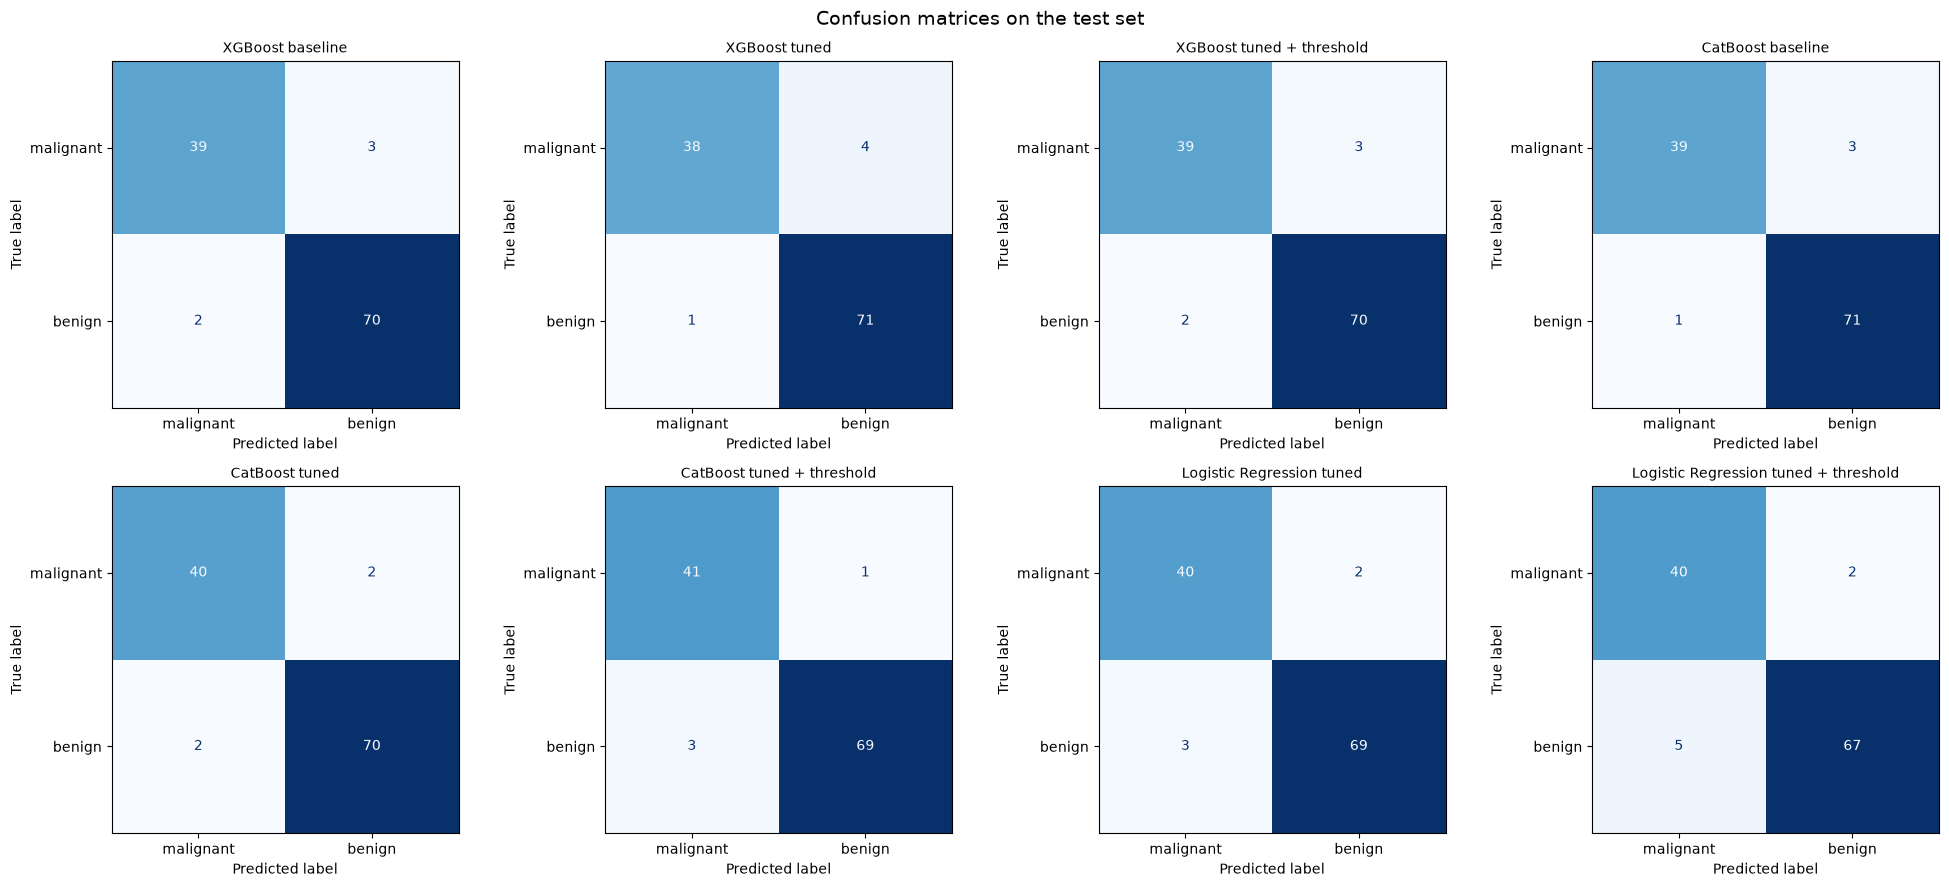

In [112]:
fig, axes = plt.subplots(2, 4, figsize=(20, 9))
for ax, (name, model) in zip(axes.flat, final_models.items()):
    ConfusionMatrixDisplay.from_estimator(model, test_X, test_y, display_labels=data.target_names,
                                          cmap='Blues', colorbar=False, ax=ax)
    ax.set_title(name, fontsize=10)
plt.suptitle('Confusion matrices on the test set', fontsize=14)
plt.tight_layout()
plt.show()

**Observations:**

- The **best** final model is **CatBoost (tuned + threshold):** it **misses only 1 of 42 malignant tumors** (recall for malignant = 97.6%, compared with 92.9% for the baseline) and produces 3 false alarms out of 72 benign samples. Accuracy stays the same (96.5%, 4 errors), but the *type* of errors changes in the desired direction: fewer dangerous false negatives, a few more false positives. Its ROC AUC is also the highest (0.996).

- **Hyperparameter tuning alone** has a mixed effect on the test set. Tuned CatBoost catches one more malignant tumor than the baseline (40/42 vs 39/42). Tuned XGBoost catches one fewer (38/42) and raises one fewer false alarm. **Threshold tuning** for XGBoost brings it back exactly to the baseline result (39/42, 2 false alarms).

- **Logistic regression**, the best model in cross-validation, is not the best on the test set (95.6% accuracy, 2 missed malignant tumors). With the tuned threshold it raises more false alarms (5) without catching any additional malignant tumors. This is a reminder that **on 114 test samples a difference of one or two samples is within random variation**. Cross-validation results, based on 15 evaluations, are the more reliable basis for comparing models.

**Summary of the improvements:**

1. `StandardScaler` does not affect gradient boosting at all. It is only needed for PCA and linear models.

2. PCA and feature selection do not improve the predictions on this small, clean and well-separable dataset. Embedded feature selection (L1) can, however, reduce the number of features from 30 to 12 almost without loss.

3. Hyperparameter tuning gives only marginal gains (≤ 0.3 pp in CV accuracy). The baseline was already close to the ceiling of these models.

4. **The most valuable improvement is tuning the decision threshold.** It doesn't increase accuracy, but it shifts the errors toward the less harmful type. For the selected CatBoost pipeline it reduced the number of missed malignant tumors on the test set from 3 to 1.

### g. What else should be done before deploying the models to production?

**Model and evaluation**

- **Validate on external data.** The dataset is small (569 samples) and comes from a single source. Before clinical use the model should be tested on data from other hospitals, devices and patient groups, to check that it generalizes.

- **Calibrate the probabilities** (`CalibratedClassifierCV`), so that a predicted "80% malignant" really means about 80%. This matters when the probability is shown to a doctor or used with a decision threshold.

- **Agree on the decision threshold with domain experts.** The acceptable trade-off between missed tumors and false alarms is a medical decision, not a purely technical one.

- **Explainability.** Feature importance or SHAP values for each prediction let a doctor see *why* the model flagged a case (essential in  domains where errors cost human lives as medicine)

- **Fairness and error analysis.** Inspect the misclassified samples and check that the model performs equally well across patient subgroups.

**Engineering**

- **Serialize the whole fitted pipeline** (preprocessing, model and threshold) as one object, e.g. with `joblib`, so that training does not have to be repeated and exactly the same transformations are applied in production as in training.

- **Pin library versions** in `requirements.txt` (e.g. `scikit-learn==1.9.1`, `xgboost==3.4.1`). A pickled pipeline may not load, or may behave differently, with other versions.

- **Validate the input data:** the expected 30 features with the correct names, order and types, no missing values, and values in plausible ranges. Invalid input should be rejected with an error rather than silently producing a prediction.

- **Reproducibility and versioning:** versioned code, data and models (e.g. MLflow or DVC), and a record of which model version made each prediction.

- **Testing:** unit tests for the preprocessing and the inference code, plus a test checking that the deployed model reproduces the predictions of the validated model.

- **Serving:** expose the model through an API (e.g. FastAPI) or batch scoring, with logging, error handling and latency checks.

**After deployment**

- **Monitor** the input data distribution (data drift) and the model's performance once true diagnoses become available (concept drift). Define alerts and criteria for retraining.

- **Human in the loop and regulation:** the model should support, not replace, the doctor's decision. Medical software is subject to regulation, which requires documentation, risk analysis and clinical validation.

Below is an example of saving the final pipeline together with its threshold, and checking that the loaded model gives identical predictions (written just for fun):

In [ ]:
final_model = threshold_models['CatBoost']

model_dir = Path('../models')
model_dir.mkdir(exist_ok=True)
model_path = model_dir / 'breast_cancer_catboost_pipeline.joblib'
joblib.dump(final_model, model_path)

loaded_model = joblib.load(model_path)
assert (loaded_model.predict(test_X) == final_model.predict(test_X)).all()
print(f'Model saved to {model_path} and reloaded successfully.')
print(f'Decision threshold for P(malignant): {loaded_model.best_threshold_:.3f}')

Model saved to ../models/breast_cancer_catboost_pipeline.joblib and reloaded successfully.
Decision threshold for P(malignant): 0.374
